# Домашнее задание 2. Вариант NLP: NER - детекция в тексте

**Дедлайн:** вс 22.11.2026, 23:59

В ДЗ2 вы выбираете **один** вариант: CV (детекция объектов на YOLO) или NLP (этот ноутбук). Номера задач и баллы в вариантах совпадают. NER (named entity recognition) - это детекция в тексте: найти спаны, т.е. непрерывные куски из слов, и для каждого предсказать тип сущности. Вы берете предобученный энкодер с Hugging Face Hub, находите свой датасет, приводите разметку к формату модели, дообучаете, считаете метрики и разбираете ошибки.

- Заполняйте места с `# ваш код` и ячейки «**Ответ:**». Сигнатуры функций и открытые тесты не меняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при проверке будут и другие входы
- В ответах опирайтесь на свои числа: наблюдение, объяснение, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация разметки + тесты), 3.1 (словарный бейзлайн), 5.1 (категоризация ошибок). Для обучения и стандартных метрик можно `transformers` (`Trainer` или свой цикл) и `seqeval`
- `FAST_MODE = True` - отладка на маленьком подмножестве, весь ноутбук не дольше 5 минут на T4. Финальный прогон - с `FAST_MODE = False`, ориентир до ~1 часа на T4. Бонусы включаются через `BONUS_TASKS`, выключенные бонусы пропускаются, даже если их ячейки пустые
- Запуск: Colab (T4) или Kaggle (GPU T4, ноутбук сам берет одну карту). Зависимости ставит первая ячейка, пины те же, что в `requirements_nlp.txt`. Укажите устройство в ячейке ниже, время обучения возвращает ваш `train_ner` (4.1)
- Только открытые модели и данные. Лицензию модели и датасета укажите в 1.1 и 2.1
- Можно документацию, материалы курса и код семинаров - укажите источник
- Сдача как в ДЗ1: PR в свой публичный GitHub-репозиторий, ссылка на него - в Google-форму (ссылку на форму дадим отдельно). В PR - ноутбук с outputs и `artifacts/metrics.json` (пишется в 5.3, перед бонусами). Датасет (`data/`), `runs/` и веса моделей не кладите, достаточно кода скачивания; файл доразметки из 6.1 - кладите
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs. Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что получилось. Ошибки не скрывайте: баллы ставятся по задачам, одна ошибка не обнуляет остальные
- ДЗ индивидуальное

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и ревизия · 1.2 архитектура | 4 |
| 2. Данные | 2.1 датасет · 2.2 формат разметки | 4 |
| 3. Бейзлайн | 3.1 бейзлайн до дообучения | 2 |
| 4. Дообучение | 4.1 обучение · 4.2 метрики | 6 |
| 5. Анализ | 5.1 разбор ошибок · 5.2 абляция · 5.3 выводы | 4 |
| 6*. Бонусы | 6.1 доразметка · 6.2 другая модель · 6.3 сдвиг · 6.4 экспорт и скорость · 6.5 пороги | до +4 из 5.5 |
| итого | | 20 + 4 |

Соответствие с CV-вариантом - задачи те же, меняется «геометрия»: вместо прямоугольника на картинке - отрезок из слов в предложении.

| CV (детекция на картинке) | NLP (NER в тексте) |
|---|---|
| бокс | спан: (начало, конец, тип) в индексах слов |
| класс объекта | тип сущности (PER, ORG, LOC, ...) |
| фон | тег `O` |
| VOC / COCO -> YOLO-формат | слова и спаны -> BIO-теги под сабворды токенизатора |
| backbone -> neck -> head | эмбеддинги -> слои энкодера -> голова token classification |
| mAP по IoU | F1 по сущностям (`seqeval`, спан засчитывается при точном совпадении границ и типа) |
| ошибка локализации (IoU 0.1-0.5) | ошибка границы спана (тип верный, спаны пересекаются) |
| ошибка класса | ошибка типа |
| пропуск / лишний бокс | пропуск / лишний спан |
| порог conf | порог уверенности спана |

Внутренности трансформера (attention, устройство слоя энкодера) - тема ДЗ3. Здесь энкодер рассматривается на уровне блоков.

Примерный план: первая неделя - разделы 1-3 (модель, датасет, разметка, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство (Colab T4 / Kaggle / свое), выбранные модель и датасет (ссылка и лицензия), бонусы, внешние источники и нерешенные задачи (если есть).

**Ответ:**
- **Устройство:** Google Colab, GPU Tesla T4; torch 2.14.1, transformers 5.22.1, datasets 5.1.0. Финальный прогон с `FAST_MODE = False`, обучение основной модели - 198 с
- **Модель:** [`FacebookAI/xlm-roberta-base`](https://huggingface.co/FacebookAI/xlm-roberta-base), revision `e73636d4f797dec63c3081bb6ed5c7b0bb3f2089`, лицензия MIT
- **Датасет:** Collection3, [`RCC-MSU/collection3`](https://huggingface.co/datasets/RCC-MSU/collection3) (ветка `refs/convert/parquet`), новости, PER / ORG / LOC, 9301 / 2153 / 1922 предложений. Лицензия в карточке - `other`, конкретные условия не указаны («Needs More Information»); датасет из списка разрешенных в задании. Статья: Mozharova, Loukachevitch, *Two-stage approach in Russian named entity recognition*, FRUCT 2016
- **Бонусы:** 6.2 (сравнение с `cointegrated/rubert-tiny2`, MIT), 6.3 (порча текста), 6.4 (fp16 / autocast), 6.5 (порог уверенности спана). Результаты - в `artifacts/bonus_metrics.json`
- **Источники:** документация Hugging Face (token classification, `Trainer`, `datasets`), документация `seqeval`, шаблон ноутбука и материалы курса; карточки модели xlm-roberta-base и датасета Collection3.
- **Нерешенные задачи:** 6.1 не делала, остальное решено

In [ ]:
# Зависимости (пины те же, что в requirements_nlp.txt). Запускайте эту ячейку первой, тогда перезапуск сессии не нужен
# Безвредный шум: строки ERROR от pip про bigframes / cudf / pyarrow на Kaggle и предупреждение про HF_TOKEN ниже (токен не нужен)
# Локально: сначала torch под свою платформу (https://pytorch.org/get-started/locally/)
%pip install -q "torch>=2.4" "transformers==5.22.1" "datasets==5.1.0" "accelerate==1.15.0" "seqeval==1.2.2" numpy matplotlib

In [ ]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')   # одна GPU: на Kaggle T4 x2 иначе Trainer включит DataParallel (медленнее и хуже)
import collections
import copy
import json
import math
import random
import re
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

import datasets
import transformers
from datasets import DatasetDict, load_dataset
from huggingface_hub import HfApi
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from transformers import (AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification,
                          Trainer, TrainingArguments)

transformers.logging.set_verbosity_error()
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

print(f'torch {torch.__version__}, transformers {transformers.__version__}, datasets {datasets.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')

torch 2.14.1+cu130, transformers 5.22.1, datasets 5.1.0
CUDA available: True


In [ ]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    transformers.set_seed(seed)


device = get_device()
DEVICE_NAME = torch.cuda.get_device_name(0) if device.type == 'cuda' else device.type
set_seed(0)
print(device, DEVICE_NAME)

cuda Tesla T4


In [ ]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = {'6.2', '6.3', '6.4', '6.5'}   # например {'6.3', '6.5'}; пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
N_TRAIN = 2000 if FAST_MODE else None   # None - весь train
N_EVAL = 500 if FAST_MODE else None     # подмножество validation и test в FAST_MODE
EPOCHS = 1 if FAST_MODE else 3
MAX_LENGTH = 128                        # длина в сабвордах, длиннее - обрезается
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
RUN_TIMES = {}

---
# 1. Модель

## 1.1 Модель и ревизия (1.5 балла)

Выберите предобученный энкодер на Hugging Face Hub, подходящий под язык и домен вашего датасета. Модель на Hub - это git-репозиторий: владелец может перезалить веса, токенизатор или конфиг, и `main` начнет указывать на другую версию. Поэтому зафиксируйте `revision` - полный commit hash (40 символов). Его видно во вкладке «Files and versions» -> «History» или через `HfApi().model_info(MODEL_ID).sha`.

Ориентиры для выбора (не исчерпывающий список):
- русский: `cointegrated/rubert-tiny2` (29M параметров, быстрый), `DeepPavlov/rubert-base-cased` (~180M)
- многоязычные: `FacebookAI/xlm-roberta-base` (~280M), `google-bert/bert-base-multilingual-cased` (~180M), `distilbert/distilbert-base-multilingual-cased`
- английский: `google-bert/bert-base-cased`, `FacebookAI/roberta-base` (в 1.1 задайте `TOKENIZER_KWARGS = {'add_prefix_space': True}`), `microsoft/deberta-v3-small`
- биомедицина: `dmis-lab/biobert-base-cased-v1.2`

Нужен fast-токенизатор: `word_ids()`, без которого не выровнять метки по сабвордам, есть только у него. На T4 модель до ~300M параметров дообучается на датасете в десятки тысяч предложений за минуты - десятки минут.

Нужен базовый энкодер, а не модель, уже дообученная на NER: с ней 3.1 и 4.1 теряют смысл.

In [ ]:
MODEL_ID = 'FacebookAI/xlm-roberta-base'
REVISION = 'e73636d4f797dec63c3081bb6ed5c7b0bb3f2089'
TOKENIZER_KWARGS = {}

In [ ]:
assert MODEL_ID, 'укажите MODEL_ID'
assert re.fullmatch(r'[0-9a-f]{40}', REVISION or ''), 'REVISION - полный commit hash из 40 символов, а не main и не тег'
info = HfApi().model_info(MODEL_ID, revision=REVISION, files_metadata=True)
card = info.card_data.to_dict() if info.card_data else {}
weights = {s.rfilename: f'{s.size / 2**20:.0f} MB' for s in info.siblings if s.rfilename.endswith(('.safetensors', '.bin'))}
print(f'model:    {MODEL_ID}\nrevision: {info.sha}\nlicense:  {card.get("license")}\nlanguage: {card.get("language")}')
print(f'updated:  {info.last_modified}\nweights:  {weights}')

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION, **TOKENIZER_KWARGS)
assert tokenizer.is_fast, 'нужен fast-токенизатор: word_ids() есть только у него'
print(type(tokenizer).__name__, 'vocab size', tokenizer.vocab_size)
print(tokenizer.tokenize('Петр Ильич Чайковский родился в Воткинске'))

model:    FacebookAI/xlm-roberta-base
revision: e73636d4f797dec63c3081bb6ed5c7b0bb3f2089
license:  mit
language: ['multilingual', 'af', 'am', 'ar', 'as', 'az', 'be', 'bg', 'bn', 'br', 'bs', 'ca', 'cs', 'cy', 'da', 'de', 'el', 'en', 'eo', 'es', 'et', 'eu', 'fa', 'fi', 'fr', 'fy', 'ga', 'gd', 'gl', 'gu', 'ha', 'he', 'hi', 'hr', 'hu', 'hy', 'id', 'is', 'it', 'ja', 'jv', 'ka', 'kk', 'km', 'kn', 'ko', 'ku', 'ky', 'la', 'lo', 'lt', 'lv', 'mg', 'mk', 'ml', 'mn', 'mr', 'ms', 'my', 'ne', 'nl', 'no', 'om', 'or', 'pa', 'pl', 'ps', 'pt', 'ro', 'ru', 'sa', 'sd', 'si', 'sk', 'sl', 'so', 'sq', 'sr', 'su', 'sv', 'sw', 'ta', 'te', 'th', 'tl', 'tr', 'ug', 'uk', 'ur', 'uz', 'vi', 'xh', 'yi', 'zh']
updated:  2024-02-19 12:48:21+00:00
weights:  {'model.safetensors': '1064 MB', 'pytorch_model.bin': '1064 MB'}
XLMRobertaTokenizer vocab size 250002
['▁Петр', '▁И', 'ль', 'ич', '▁Ча', 'й', 'ковски', 'й', '▁родился', '▁в', '▁Вот', 'ки', 'нске']


**Вопрос.** Почему вы выбрали эту модель: язык и данные предобучения, размер и скорость, ожидаемое качество на NER, лицензия? Сравните с 1-2 альтернативами из списка выше: размер, язык, скорость, качество по карточке. Что может сломаться в вашем ноутбуке через полгода, если не фиксировать `revision`?

**Ответ:** Я взяла модель `xlm-roberta-base` (277M параметров, 12 слоёв). Её обучали на текстах на 100 языках, русский среди них есть, и представлен хорошо. Она часто используется для NER и обычно даёт хорошее качество. В новостях из Collection3 попадаются иностранные названия на латинице, а многоязычная модель знает и их. Лицензия MIT, то есть модель открытая.

Альтернативы:
- `cointegrated/rubert-tiny2`: маленькая (29M параметров), только для русского, работает гораздо быстрее, но качество ниже. В 6.2 она дала F1 0.929 против 0.967.
- `DeepPavlov/rubert-base-cased`: хорошая русская модель, но в её карточке не указана лицензия, поэтому я её не брала.

По времени всё укладывается: на GPU T4 модель обучается за 198 секунд, так что в час помещаются и основное обучение, и абляция, и бонусы.

Зачем фиксировать `revision`: если загружать последнюю версию (`main`), через полгода автор может обновить веса или токенизатор. Тогда слова будут иначе делиться на части, получатся другие результаты, а ноутбук может вообще перестать запускаться. Точный хэш версии гарантирует, что модель всегда будет та же.

## 1.2 Архитектура (2.5 балла)

Энкодер для token classification на уровне блоков:

1. **эмбеддинги** - сабворд -> вектор размера hidden (таблица `vocab_size x hidden`) + позиционные эмбеддинги (у DeBERTa их нет, позиции учитываются в attention) и type-эмбеддинги (у BERT-подобных), LayerNorm, dropout. Выход `(B, T, H)`
2. **N слоев энкодера** - одинаковые по форме блоки `(B, T, H) -> (B, T, H)`, в которых токены обмениваются информацией друг с другом. Устройство слоя (attention, FFN) - ДЗ3
3. **голова token classification** - dropout + `Linear(H, K)` к каждому токену независимо, K - число BIO-тегов. Выход - logits `(B, T, K)`
4. **сборка спанов** - argmax по тегам на первом сабворде каждого слова, затем BIO -> спаны (это уже не нейросеть, а ваш код из 2.2)

Ниже модель создается с головой на `N_DEMO_LABELS = 7` тегов (O + B/I для трех типов), под ваш датасет голову пересоздает `make_model` (3.1, 4.1).

1. Реализуйте `params_by_block(model)` - число параметров по блокам: `embeddings`, `encoder` (все слои), `head` (классификатор), `other` (все остальное: у BERT и RoBERTa для token classification здесь 0, у DeBERTa - `encoder.rel_embeddings` и общий `encoder.LayerNorm`) и `layers` - список по слоям энкодера. Сумма блоков должна совпасть с общим числом параметров
2. Прогоните dummy-вход `demo_texts` (батч из двух предложений, уже разбитых на слова) через токенизатор и модель с `output_hidden_states=True`, сохраните результат токенизатора в `enc`, выход модели в `out` и выведите формы: `input_ids`, `attention_mask`, все `hidden_states`, `logits`

In [ ]:
N_DEMO_LABELS = 7
demo_model = AutoModelForTokenClassification.from_pretrained(MODEL_ID, revision=REVISION, num_labels=N_DEMO_LABELS)
cfg = demo_model.config
print({k: getattr(cfg, k, None) for k in ['model_type', 'vocab_size', 'hidden_size', 'num_hidden_layers',
                                          'num_attention_heads', 'intermediate_size', 'max_position_embeddings']})
for name, module in demo_model.named_children():
    print(f'{name:<12} {type(module).__name__}')

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'model_type': 'xlm-roberta', 'vocab_size': 250002, 'hidden_size': 768, 'num_hidden_layers': 12, 'num_attention_heads': 12, 'intermediate_size': 3072, 'max_position_embeddings': 514}
dropout      Dropout
classifier   Linear
roberta      XLMRobertaModel


In [ ]:
def n_params(module):
    return sum(p.numel() for p in module.parameters())


def params_by_block(model):
    base = model.base_model
    layers = [n_params(layer) for layer in base.encoder.layer]
    embeddings = n_params(base.embeddings)
    head = n_params(model.classifier)
    other = n_params(model) - embeddings - sum(layers) - head
    return dict(embeddings=embeddings, encoder=sum(layers), head=head, other=other, layers=layers)

In [ ]:
blocks = params_by_block(demo_model)
total = sum(p.numel() for p in demo_model.parameters())
assert sum(blocks[k] for k in ['embeddings', 'encoder', 'head', 'other']) == total
assert blocks['head'] == cfg.hidden_size * N_DEMO_LABELS + N_DEMO_LABELS
assert len(blocks['layers']) == cfg.num_hidden_layers and sum(blocks['layers']) == blocks['encoder'], \
    'encoder - сумма слоев, все вне слоев (например, rel_embeddings у DeBERTa) - в other'
assert blocks['embeddings'] >= cfg.vocab_size * cfg.hidden_size
for k in ['embeddings', 'encoder', 'head', 'other']:
    print(f'{k:<11}{blocks[k]:>13,}  {blocks[k] / total:6.1%}')
print(f'{"total":<11}{total:>13,}\nper layer: {blocks["layers"]}')

embeddings   192,398,592   69.3%
encoder       85,054,464   30.7%
head               5,383    0.0%
other                  0    0.0%
total        277,458,439
per layer: [7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872]


In [ ]:
demo_texts = [['Петр', 'Чайковский', 'родился', 'в', 'Воткинске', '.'],
              ['ITMO', 'University', 'is', 'in', 'Saint', 'Petersburg']]
enc = tokenizer(demo_texts, is_split_into_words=True, padding=True, return_tensors='pt')
demo_model.eval()
with torch.no_grad():
    out = demo_model(**enc, output_hidden_states=True)

for i in range(len(demo_texts)):
    print(list(zip(enc.tokens(i), enc.word_ids(i))))
print('input_ids     ', tuple(enc['input_ids'].shape))
print('attention_mask', tuple(enc['attention_mask'].shape))
for i, h in enumerate(out.hidden_states):
    print(f'hidden_states[{i:>2}]', tuple(h.shape), '<- эмбеддинги' if i == 0 else f'<- слой {i}')
print('logits        ', tuple(out.logits.shape))

[('<s>', None), ('▁Петр', 0), ('▁Ча', 1), ('й', 1), ('ковски', 1), ('й', 1), ('▁родился', 2), ('▁в', 3), ('▁Вот', 4), ('ки', 4), ('нске', 4), ('▁', 5), ('.', 5), ('</s>', None)]
[('<s>', None), ('▁IT', 0), ('MO', 0), ('▁University', 1), ('▁is', 2), ('▁in', 3), ('▁Saint', 4), ('▁Petersburg', 5), ('</s>', None), ('<pad>', None), ('<pad>', None), ('<pad>', None), ('<pad>', None), ('<pad>', None)]
input_ids      (2, 14)
attention_mask (2, 14)
hidden_states[ 0] (2, 14, 768) <- эмбеддинги
hidden_states[ 1] (2, 14, 768) <- слой 1
hidden_states[ 2] (2, 14, 768) <- слой 2
hidden_states[ 3] (2, 14, 768) <- слой 3
hidden_states[ 4] (2, 14, 768) <- слой 4
hidden_states[ 5] (2, 14, 768) <- слой 5
hidden_states[ 6] (2, 14, 768) <- слой 6
hidden_states[ 7] (2, 14, 768) <- слой 7
hidden_states[ 8] (2, 14, 768) <- слой 8
hidden_states[ 9] (2, 14, 768) <- слой 9
hidden_states[10] (2, 14, 768) <- слой 10
hidden_states[11] (2, 14, 768) <- слой 11
hidden_states[12] (2, 14, 768) <- слой 12
logits         (2

In [ ]:
B, T = enc['input_ids'].shape
assert B == 2 and out.logits.shape == (B, T, N_DEMO_LABELS)
assert len(out.hidden_states) == cfg.num_hidden_layers + 1
assert all(h.shape == (B, T, cfg.hidden_size) for h in out.hidden_states)

# скорость прямого прохода: батч 32 предложения x 62 слова (сколько это сабвордов - см. вывод)
x = {k: v.to(device) for k, v in tokenizer([['слово'] * 62] * 32, is_split_into_words=True, return_tensors='pt').items()}
demo_model.to(device).eval()
with torch.inference_mode():
    demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(5):
        demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
print(f'forward 32 x {x["input_ids"].shape[1]}: {(time.perf_counter() - start) / 5 * 1000:.1f} ms на {DEVICE_NAME}')
demo_model = demo_model.cpu()

forward 32 x 64: 104.5 ms на Tesla T4


**Вопрос.** Опишите путь входа по блокам с формами тензоров из вашего вывода. Какой блок содержит больше всего параметров и почему? В каком блоке токены обмениваются информацией, а где каждый токен обрабатывается независимо? Почему `T` в logits больше числа слов?

**Ответ:** На вход подаётся батч из 2 предложений. Токенизатор превращает их в `input_ids` и `attention_mask` размера `(2, 14)`: 14 токенов, потому что слова делятся на части (сабворды), добавляются служебные токены `<s>` и `</s>`, а короткое предложение добивается паддингом. Например, «Чайковский» делится на 4 части: `▁Ча`, `й`, `ковски`, `й`.

Дальше слой эмбеддингов превращает каждый токен в вектор длины 768, получается `(2, 14, 768)`. Затем 12 слоёв энкодера, размер не меняется. Поэтому `hidden_states` — это 13 тензоров `(2, 14, 768)`: эмбеддинги и выход каждого слоя. Голова — один линейный слой 768 → 7, он даёт logits `(2, 14, 7)`, по 7 оценок (тегов) на каждый токен.

Больше всего параметров в эмбеддингах: 192M из 277M (69%), потому что словарь огромный, 250 тысяч токенов на разных языках. В энкодере 85M (31%, примерно по 7M на слой), в голове всего 5383 параметра.

Токены «общаются» друг с другом только в слоях энкодера (через self-attention). Эмбеддинги и голова обрабатывают каждый токен отдельно.

---
# 2. Данные

## 2.1 Датасет (1.5 балла)

Найдите датасет для NER на Hugging Face Hub или в другом открытом источнике, подходящий под вашу модель по языку. Опишите источник, лицензию, как размечали, типы сущностей, размер и сплиты; посчитайте статистику: число сущностей каждого типа по сплитам, распределение длин спанов (в словах), длины предложений.

**Нельзя брать WikiANN ru** (`unimelb-nlp/wikiann`, конфиг `ru`) - на нем ниже показан пример формата. Другие языки WikiANN брать можно.

Подсказки - датасеты, которые на момент выдачи загружаются текущей библиотекой `datasets` (проверено 31.10.2026, `datasets` 5.1). Библиотека больше не исполняет loading-скрипты, поэтому часть датасетов грузится из служебной ветки с parquet-версией - так, как написано в списке:

Русский:
- `Babelscape/wikineural` - WikiNEuRal, PER / ORG / LOC / MISC, 9 языков; для русского сплиты `train_ru`, `val_ru`, `test_ru`; CC BY-NC-SA 4.0
- `Babelscape/multinerd` - MultiNERD, 15 типов, 10 языков, колонка `lang` - отфильтруйте `ru`; CC BY-NC-SA 4.0
- `load_dataset('RCC-MSU/collection3', revision='refs/convert/parquet')` - Collection3, новости, PER / ORG / LOC, уже `tokens` + `ner_tags`
- `undefinedhorizons/nerus_lenta` - Nerus: новости Lenta.ru с автоматической разметкой PER / LOC / ORG, только `train` и очень большой - возьмите подмножество и сами отделите validation и test
- `gusevski/factrueval2016` - FactRuEval-2016, новости; вся разметка в одной вложенной колонке `data` - разобрать в предложения, слова и BIO
- `load_dataset('iluvvatar/RuNNE', revision='refs/convert/parquet')` и то же для `iluvvatar/NEREL` - новости, 29 типов, вложенные сущности, спаны по символам в тексте. Нужны разбиение на предложения и слова (целый текст длиннее `MAX_LENGTH = 128` сабвордов, хвост обрежется), BIO и правило для вложенных (например, оставить только внешние) - самая содержательная конвертация из списка

Другие языки:
- `unimelb-nlp/wikiann` - WikiANN, 176 языков (любой, кроме `ru`), PER / ORG / LOC
- `lhoestq/conll2003`, `tomaarsen/conll2003` или `load_dataset('eriktks/conll2003', revision='refs/convert/parquet')` - CoNLL-2003, английский, PER / ORG / LOC / MISC
- `DFKI-SLT/few-nerd`, конфиг `supervised` - Few-NERD, английский, 8 крупных и 66 мелких типов; теги в IO-схеме (без `B-` и `I-`) - переведите в BIO; CC BY-SA 4.0
- `load_dataset('tner/wnut2017', revision='refs/convert/parquet')` - WNUT-17, соцсети, редкие и новые сущности; имена тегов - в файле `dataset/label.json` репозитория

Биомедицина (английский):
- `load_dataset('ncbi/ncbi_disease', revision='refs/convert/parquet')` - NCBI-disease, один тип Disease
- `load_dataset('tner/bc5cdr', revision='refs/convert/parquet')` - BC5CDR, Chemical / Disease, теги в колонке `tags`: `{"O": 0, "B-Chemical": 1, "B-Disease": 2, "I-Disease": 3, "I-Chemical": 4}`

Если `load_dataset('<id>')` падает из-за loading-скрипта, берите ветку `revision='refs/convert/parquet'` (как в списке) или сырые файлы: `load_dataset('json', data_files='hf://datasets/<id>/<путь к файлу>')`. Датасеты из списка разрешены, лицензию укажите, как в карточке.

Если сплита validation или test нет, отделите их сами (`train_test_split` с фиксированным seed). Если датасет очень большой, возьмите подмножество и укажите это.

Контракт для остального ноутбука (после 2.2): `raw` - `DatasetDict` со сплитами `train`, `validation`, `test`, у каждого примера `tokens` (список слов) и `ner_tags` (список id тегов той же длины); `LABEL_NAMES` - список BIO-тегов, `LABEL_NAMES[i]` - тег с id `i`, тег `O` обязателен.

Если у `ner_tags` нет имен тегов (в `features` список чисел, а не `ClassLabel`; так у WikiNEuRal, MultiNERD и `lhoestq/conll2003`), составьте `LABEL_NAMES` вручную по карточке датасета. Например, у WikiNEuRal: `['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']`.

In [ ]:
# пример формата на WikiANN ru (этот датасет брать нельзя)
example = load_dataset('unimelb-nlp/wikiann', 'ru', split='validation[:3]')
print(example)
print(example.features['ner_tags'].feature.names)
for ex in example:
    print(list(zip(ex['tokens'], ex['ner_tags'])), ex['spans'])

Dataset({
    features: ['tokens', 'ner_tags', 'langs', 'spans'],
    num_rows: 3
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
[('Отличился', 0), ('во', 0), ('время', 0), ('боёв', 0), ('в', 0), ('Германии', 5), ('.', 0)] ['LOC: Германии']
[('1920—1922', 0), ('—', 0), ('техник', 0), ('военно-гидротехнического', 0), ('отряда', 0), ('(', 0), ('Чернигов', 5), (')', 0), (',', 0)] ['LOC: Чернигов']
[('Нагибин', 1), (',', 2), ('Владимир', 2), ('Владимирович', 2)] ['PER: Нагибин , Владимир Владимирович']


In [ ]:
from seqeval.metrics.sequence_labeling import get_entities

DATASET_ID, DATASET_CONFIG = 'RCC-MSU/collection3', None
DATASET_REVISION = 'refs/convert/parquet'
CARD_LABELS = ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']

raw = load_dataset(DATASET_ID, revision=DATASET_REVISION)
tag_feature = getattr(raw['train'].features['ner_tags'], 'feature', None)
LABEL_NAMES = list(getattr(tag_feature, 'names', None) or CARD_LABELS)
print(raw)
print('LABEL_NAMES', LABEL_NAMES, '(из features)' if getattr(tag_feature, 'names', None) else '(по карточке датасета)')

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 9301
    })
    validation: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 2153
    })
    test: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 1922
    })
})
LABEL_NAMES ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC'] (из features)


split         предл.     слов     LOC     ORG     PER   всего  сущ./предл.
train           9301   187656    4881    5960    7406   18247         1.96
validation      2153    43856    1168    1308    1641    4117         1.91
test            1922    40260    1175    1256    1570    4001         2.08

длина спана в словах (train): среднее / медиана / максимум
  LOC: 1.32 / 1 / 8   доля однословных 78%
  ORG: 2.00 / 1 / 18   доля однословных 54%
  PER: 2.01 / 2 / 10   доля однословных 27%
длина предложения train: среднее 20.2, медиана 18, максимум 256, пустых 0, без сущностей 1815
длина предложения validation: среднее 20.4, медиана 18, максимум 118, пустых 0, без сущностей 504
длина предложения test: среднее 20.9, медиана 19, максимум 122, пустых 0, без сущностей 351


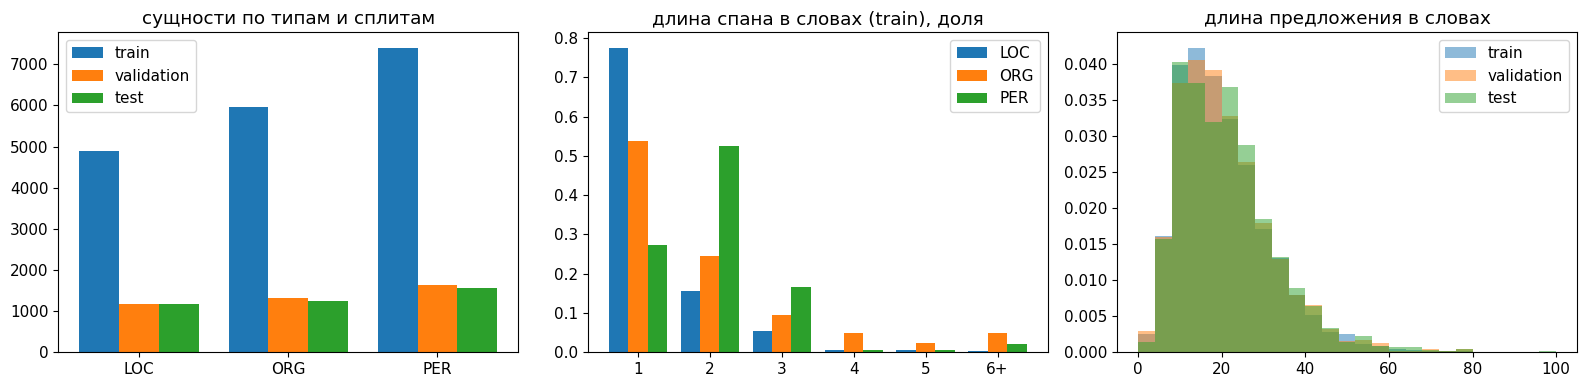

In [ ]:
def to_tags(ids):
    return [LABEL_NAMES[i] for i in ids]


entity_counts, span_lengths, sentence_lengths = {}, {}, {}
for split in raw:
    counts, lengths = collections.Counter(), collections.defaultdict(list)
    for ids in raw[split]['ner_tags']:
        for kind, start, end in get_entities(to_tags(ids)):
            counts[kind] += 1
            lengths[kind].append(end - start + 1)
    entity_counts[split], span_lengths[split] = counts, lengths
    sentence_lengths[split] = [len(ws) for ws in raw[split]['tokens']]

types = sorted({t for c in entity_counts.values() for t in c})
print(f'{"split":<12}{"предл.":>8}{"слов":>9}' + ''.join(f'{t:>8}' for t in types) + f'{"всего":>8}{"сущ./предл.":>13}')
for split in raw:
    c, n = entity_counts[split], len(raw[split])
    print(f'{split:<12}{n:>8}{sum(sentence_lengths[split]):>9}' + ''.join(f'{c[t]:>8}' for t in types)
          + f'{sum(c.values()):>8}{sum(c.values()) / n:>13.2f}')

train_lengths = span_lengths['train']
print('\nдлина спана в словах (train): среднее / медиана / максимум')
for t in types:
    v = np.array(train_lengths[t])
    print(f'  {t}: {v.mean():.2f} / {np.median(v):.0f} / {v.max()}   доля однословных {np.mean(v == 1):.0%}')
for split in raw:
    v = np.array(sentence_lengths[split])
    print(f'длина предложения {split}: среднее {v.mean():.1f}, медиана {np.median(v):.0f}, '
          f'максимум {v.max()}, пустых {np.sum(v == 0)}, без сущностей {sum(1 for ids in raw[split]["ner_tags"] if not any(ids))}')

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
width = 0.8 / len(raw)
for k, split in enumerate(raw):
    axes[0].bar(np.arange(len(types)) + k * width, [entity_counts[split][t] for t in types], width, label=split)
axes[0].set_xticks(np.arange(len(types)) + width * (len(raw) - 1) / 2, types)
axes[0].set_title('сущности по типам и сплитам')
axes[0].legend()
max_len = 6
for k, t in enumerate(types):
    v = np.minimum(train_lengths[t], max_len)
    share = [np.mean(v == L) for L in range(1, max_len + 1)]
    axes[1].bar(np.arange(1, max_len + 1) + (k - 1) * 0.27, share, 0.27, label=t)
axes[1].set_xticks(range(1, max_len + 1), [str(i) for i in range(1, max_len)] + [f'{max_len}+'])
axes[1].set_title('длина спана в словах (train), доля')
axes[1].legend()
for split in raw:
    axes[2].hist(sentence_lengths[split], bins=np.arange(0, 101, 4), alpha=0.5, density=True, label=split)
axes[2].set_title('длина предложения в словах')
axes[2].legend()
plt.tight_layout()
plt.show()

**Вопрос.** Откуда датасет, под какой лицензией и как его размечали (вручную, автоматически, полуавтоматически)? Какие типы сущностей, сколько их по сплитам, какие типы редкие? Какие особенности данных (длина спанов, длина предложений, шум разметки) могут повлиять на обучение?

**Ответ:** Collection3 — русские новостные тексты, размеченные вручную. Типы сущностей: PER (люди), ORG (организации), LOC (места). Лицензия в карточке не уточнена (`other`), но датасет есть в списке разрешённых.

Размер: train / validation / test = 9301 / 2153 / 1922 предложения, сущностей 18247 / 4117 / 4001. Типы примерно сбалансированы: в train 7406 PER, 5960 ORG, 4881 LOC.

Длина сущностей разная: LOC почти всегда из одного слова (78%), PER обычно из двух (имя и фамилия), а ORG бывают очень длинные, до 18 слов («Министерство ...»). Поэтому заранее ожидаю, что ORG будет самым сложным.

Предложения в среднем по 20 слов, но встречаются очень длинные (до 256 слов), они не влезут в лимит 128 сабвордов. Примерно 20% предложений вообще без сущностей.

## 2.2 Формат разметки (2.5 балла)

Модель предсказывает тег для каждого **сабворда**, а разметка дана по **словам** (или спанами по символам). Нужны две конвертации и тесты к ним.

1. `bio_to_spans(tags)` - BIO-теги слов -> список спанов `(start, end, type)`, `end` не включается. `B-X` начинает спан, `I-X` продолжает спан того же типа, иначе начинает новый (так делает `seqeval` в режиме по умолчанию), `O` закрывает спан. Тип может содержать дефис (`B-art-film` -> `art-film`)
2. `spans_to_bio(spans, n_words)` - обратно: спаны -> BIO-теги длины `n_words`
3. `align_labels(word_labels, word_ids, b_to_i=None)` - метки слов -> метки сабвордов. `word_ids` - выход `tokenizer(...).word_ids(i)`: номер слова для каждого сабворда, `None` у спецтокенов. По умолчанию метка слова ставится на его первый сабворд, спецтокены и продолжения слова получают `-100` (cross-entropy их игнорирует). Если передан словарь `b_to_i` (id тега `B-X` -> id тега `I-X`), метку получают все сабворды слова, у продолжений `B-X` заменяется на `I-X` - это вариант для абляции 5.2

Если ваш датасет не в формате «слова + BIO» (спаны по символам, IO-теги, CoNLL-текст), сначала приведите его к контракту из 2.1 и проверьте конвертацию на примерах глазами. Если датасет уже в BIO, сделайте обратную конвертацию: BIO -> спаны в JSON (`data/<split>_spans.jsonl`), прочитайте файл обратно, сконвертируйте в BIO и проверьте, что получилось то же самое (если в исходнике есть `I-X` без `B-X`, дословно не совпадет: сравните спаны и посчитайте такие предложения).

In [ ]:
def bio_to_spans(tags):
    spans, start, kind = [], None, None
    for i, tag in enumerate(list(tags) + ['O']):
        prefix, _, name = tag.partition('-')
        if start is not None and (prefix != 'I' or name != kind):
            spans.append((start, i, kind))
            start = None
        if prefix == 'B' or (prefix == 'I' and start is None):
            start, kind = i, name
    return spans


def spans_to_bio(spans, n_words):
    tags = ['O'] * n_words
    for start, end, kind in spans:
        tags[start] = 'B-' + kind
        for i in range(start + 1, end):
            tags[i] = 'I-' + kind
    return tags


def align_labels(word_labels, word_ids, b_to_i=None):
    labels, previous = [], None
    for w in word_ids:
        if w is None:
            labels.append(-100)
        elif w != previous:
            labels.append(word_labels[w])
        elif b_to_i is None:
            labels.append(-100)
        else:
            labels.append(b_to_i.get(word_labels[w], word_labels[w]))
        previous = w
    return labels

In [ ]:
tags = ['B-PER', 'I-PER', 'O', 'B-LOC', 'B-LOC', 'I-LOC', 'O', 'B-ORG']
assert bio_to_spans(tags) == [(0, 2, 'PER'), (3, 4, 'LOC'), (4, 6, 'LOC'), (7, 8, 'ORG')]
assert spans_to_bio(bio_to_spans(tags), len(tags)) == tags
assert bio_to_spans(['O', 'I-PER', 'I-PER', 'O']) == [(1, 3, 'PER')]       # I- без B- начинает спан
assert bio_to_spans(['B-PER', 'I-LOC', 'I-LOC']) == [(0, 1, 'PER'), (1, 3, 'LOC')]
assert bio_to_spans(['B-art-film', 'I-art-film', 'O']) == [(0, 2, 'art-film')]
assert bio_to_spans([]) == [] and bio_to_spans(['O'] * 3) == [] and spans_to_bio([], 2) == ['O', 'O']

rng = random.Random(0)
for _ in range(2000):   # туда-обратно на случайных спанах
    n, pos, spans = rng.randint(0, 15), 0, []
    while True:
        start = pos + rng.randint(0, 3)
        end = start + rng.randint(1, 4)
        if end > n:
            break
        spans.append((start, end, rng.choice(['PER', 'LOC', 'ORG'])))
        pos = end
    assert bio_to_spans(spans_to_bio(spans, n)) == spans, spans

word_ids = [None, 0, 0, 1, 2, 2, 2, None]
assert align_labels([1, 0, 3], word_ids) == [-100, 1, -100, 0, 3, -100, -100, -100]
assert align_labels([1, 0, 3], word_ids, b_to_i={1: 2, 3: 4}) == [-100, 1, 2, 0, 3, 4, 4, -100]
assert align_labels([2, 6], [None, 0, 0, 1, None], b_to_i={1: 2, 5: 6}) == [-100, 2, 2, 6, -100]
assert align_labels([5, 6, 0], [None, 0, None]) == [-100, 5, -100]        # обрезка по MAX_LENGTH
print('ok')

ok


In [ ]:
DATA_DIR = Path('data')
DATA_DIR.mkdir(exist_ok=True)


def export_spans(ds, path):
    with open(path, 'w', encoding='utf-8') as f:
        for ex in ds:
            item = dict(tokens=list(ex['tokens']), spans=bio_to_spans(to_tags(ex['ner_tags'])))
            f.write(json.dumps(item, ensure_ascii=False) + '\n')


def read_spans(path):
    with open(path, encoding='utf-8') as f:
        items = [json.loads(line) for line in f]
    return [(item['tokens'], [tuple(s) for s in item['spans']]) for item in items]


conversion, bad_bio = {}, []
for split in raw:
    path = DATA_DIR / f'{split}_spans.jsonl'
    export_spans(raw[split], path)
    back = read_spans(path)
    assert len(back) == len(raw[split])
    same_bio = same_spans = n_spans = 0
    for (words, spans), ex in zip(back, raw[split]):
        original = to_tags(ex['ner_tags'])
        restored = spans_to_bio(spans, len(words))
        assert list(words) == list(ex['tokens']) and len(restored) == len(original)
        same_bio += restored == original
        same_spans += bio_to_spans(restored) == bio_to_spans(original) == spans
        n_spans += len(spans)
        if restored != original and len(bad_bio) < 5:
            bad_bio.append((split, words, original, restored))
    conversion[split] = dict(sentences=len(back), spans=n_spans, same_bio=same_bio, same_spans=same_spans,
                             invalid_bio=len(back) - same_bio)
    assert same_spans == len(back), split

for split, c in conversion.items():
    print(f'{split:<11} предложений {c["sentences"]:>6}, спанов {c["spans"]:>6}, BIO совпал дословно {c["same_bio"]:>6}, '
          f'спаны совпали {c["same_spans"]:>6}, невалидный BIO (I- без B-) {c["invalid_bio"]}')
for split, words, original, restored in bad_bio:
    diff = [i for i, (a, b) in enumerate(zip(original, restored)) if a != b]
    lo, hi = max(0, diff[0] - 3), diff[-1] + 4
    print(f'\n{split}:', list(zip(words[lo:hi], original[lo:hi], restored[lo:hi])))
print('\nпример строки jsonl:', (DATA_DIR / 'train_spans.jsonl').open(encoding='utf-8').readline()[:300])

train       предложений   9301, спанов  18247, BIO совпал дословно   9296, спаны совпали   9301, невалидный BIO (I- без B-) 5
validation  предложений   2153, спанов   4117, BIO совпал дословно   2153, спаны совпали   2153, невалидный BIO (I- без B-) 0
test        предложений   1922, спанов   4001, BIO совпал дословно   1921, спаны совпали   1922, невалидный BIO (I- без B-) 1

train: [('Воробьева', 'B-PER', 'B-PER'), ('и', 'O', 'O'), ('.', 'O', 'O'), ('о', 'I-PER', 'B-PER'), ('.', 'O', 'O'), ('главы', 'O', 'O'), ('Подмосковья', 'B-LOC', 'B-LOC')]

train: [('Власть', 'I-ORG', 'B-ORG'), ('"', 'O', 'O'), ('Вероника', 'B-PER', 'B-PER'), ('Куцылло', 'I-PER', 'I-PER')]

train: [('Ответственность', 'I-ORG', 'B-ORG'), ('.', 'I-ORG', 'I-ORG')]

train: [('Процветание', 'I-ORG', 'B-ORG'), ('09', 'I-ORG', 'I-ORG'), ('"', 'I-ORG', 'I-ORG'), ('(', 'I-ORG', 'I-ORG')]

train: [('Северный', 'I-ORG', 'B-ORG'), ('Кавказ', 'I-ORG', 'I-ORG'), ('"', 'O', 'O'), (',', 'O', 'O')]

пример строки jsonl: {"tokens"

In [ ]:
assert isinstance(raw, DatasetDict) and isinstance(LABEL_NAMES, list), 'raw и LABEL_NAMES - из 2.1 (после конвертации в 2.2)'
assert {'train', 'validation', 'test'} <= set(raw), 'нужны сплиты train / validation / test'
assert {'tokens', 'ner_tags'} <= set(raw['train'].column_names)
assert 'O' in LABEL_NAMES and all(re.fullmatch(r'O|[BI]-.+', t) for t in LABEL_NAMES), LABEL_NAMES
label2id = {t: i for i, t in enumerate(LABEL_NAMES)}
id2label = dict(enumerate(LABEL_NAMES))
ENTITY_TYPES = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
B_TO_I = {label2id[t]: label2id['I-' + t[2:]] for t in LABEL_NAMES if t.startswith('B-') and 'I-' + t[2:] in label2id}


def subset(ds, n):
    return ds if n is None else ds.shuffle(seed=SEED).select(range(min(n, len(ds))))


data = DatasetDict(train=subset(raw['train'], N_TRAIN), validation=subset(raw['validation'], N_EVAL),
                   test=subset(raw['test'], N_EVAL))


def tokenize_and_align(batch, tok=None, label_all_subwords=False):
    tok = tok or tokenizer
    enc = tok(batch['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    enc['labels'] = [align_labels(tags, enc.word_ids(i), B_TO_I if label_all_subwords else None)
                     for i, tags in enumerate(batch['ner_tags'])]
    return enc


tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names)
print(data)
print('ENTITY_TYPES', ENTITY_TYPES)

# проверка на реальных данных: метки первых сабвордов восстанавливают метки слов, спаны совпадают
n_truncated = n_lost_words = n_checked = 0
for ex in data['train']:
    enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    ids = enc.word_ids()
    labels = align_labels(ex['ner_tags'], ids)
    got = {w: l for w, l in zip(ids, labels) if l != -100}
    assert got == {w: ex['ner_tags'][w] for w in set(ids) - {None}}
    n_truncated += len(enc['input_ids']) == MAX_LENGTH
    n_lost = len(ex['tokens']) - len(got)
    n_lost_words += n_lost
    if n_lost == 0:
        back = [LABEL_NAMES[got[w]] for w in range(len(ex['tokens']))]
        assert bio_to_spans(back) == bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
        n_checked += 1
print(f'train: проверено {n_checked} предложений, обрезано по MAX_LENGTH {n_truncated}, слов без сабвордов или за обрезкой {n_lost_words}')

ex = data['train'][0]
enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
for sub, w, l in zip(enc.tokens(), enc.word_ids(), align_labels(ex['ner_tags'], enc.word_ids())):
    print(f'{sub:<16}{str(w):>5}  {LABEL_NAMES[l] if l != -100 else -100}')

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 9301
    })
    validation: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 2153
    })
    test: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 1922
    })
})
ENTITY_TYPES ['LOC', 'ORG', 'PER']
train: проверено 9275 предложений, обрезано по MAX_LENGTH 27, слов без сабвордов или за обрезкой 886
<s>              None  -100
▁До                 0  O
полнение            0  -100
▁:                  1  O
▁Д                  2  B-PER
▁                   3  I-PER
.                   3  -100
▁Медведев           4  I-PER
▁при                5  O
сво                 5  -100
ил                  5  -100
▁з                  6  O
вания               6  -100
▁сотрудников        7  O
▁полиции            8  O
▁и                  9  O
▁пере              10  O
на                 10  -100
значи              10  -100
л                  10  -100
▁14    

**Вопрос.** Почему метка ставится только на первый сабворд, а остальным -100, и что -100 делает в loss? Сколько предложений обрезано по `MAX_LENGTH` и сколько слов не получили ни одного сабворда - как это повлияет на метрику? Какие проблемы нашлись при конвертации вашего датасета (невалидный BIO, пересекающиеся или вложенные спаны, расхождение токенизации)?

**Ответ:** Метку ставлю только на первую часть слова, чтобы у каждого слова было ровно одно предсказание. Иначе длинные слова, которые делятся на много частей, весили бы в обучении больше коротких. `-100` означает «игнорировать»: на этих позициях (служебные токены, продолжения слов, паддинг) ошибка не считается.

27 предложений из 9301 оказались длиннее 128 сабвордов и обрезаны. Из-за этого 886 слов (0.5%) остались без метки. Это мало, но сущности в обрезанных хвостах модель гарантированно пропустит.

Конвертация BIO → спаны → BIO вернула все сущности без потерь. Дословно BIO не совпал только в 6 предложениях (5 в train, 1 в test): там разметка начинается с `I-` без `B-`. В основном это ошибки разбиения текста на предложения: начало названия ушло в предыдущее предложение.

---
# 3. Бейзлайн

## 3.1 Бейзлайн до дообучения (2 балла)

Метрики считаются по словам: тег слова - предсказание на его первом сабворде (функция `predict_word_tags` ниже). F1 по сущностям - `seqeval`: спан засчитывается, только если совпали обе границы и тип.

1. Реализуйте словарный бейзлайн: `fit_majority_tagger` запоминает для каждого слова из train самый частый его тег, `predict_majority` размечает предложение, незнакомые слова получают `O`
2. Посчитайте метрики бейзлайна и энкодера со случайно инициализированной головой (без дообучения) на validation

In [ ]:
@torch.no_grad()
def predict_word_tags(model, tokens_list, tok=None, batch_size=64, return_probs=False, dev=None):
    # теги слов по первому сабворду; слова без сабвордов или за MAX_LENGTH получают 'O' (вероятность 1)
    tok, dev = tok or tokenizer, dev or device
    tokens_list = [list(ws) for ws in tokens_list]
    model.eval().to(dev)
    all_tags, all_probs = [], []
    for start in range(0, len(tokens_list), batch_size):
        batch = tokens_list[start:start + batch_size]
        enc = tok(batch, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')
        probs = model(**{k: v.to(dev) for k, v in enc.items()}).logits.float().softmax(-1).cpu()
        conf, best = probs.max(-1)
        for i, words in enumerate(batch):
            tags, word_conf, seen = ['O'] * len(words), [1.0] * len(words), set()
            for pos, w in enumerate(enc.word_ids(i)):
                if w is None or w in seen:
                    continue
                seen.add(w)
                tags[w], word_conf[w] = model.config.id2label[int(best[i, pos])], float(conf[i, pos])
            all_tags.append(tags)
            all_probs.append(word_conf)
    return (all_tags, all_probs) if return_probs else all_tags


def entity_scores(gold, pred):
    return dict(f1_micro=f1_score(gold, pred, average='micro', zero_division=0),
                f1_macro=f1_score(gold, pred, average='macro', zero_division=0),
                precision=precision_score(gold, pred, zero_division=0),
                recall=recall_score(gold, pred, zero_division=0))


def make_model(model_id=None, revision=None):
    return AutoModelForTokenClassification.from_pretrained(
        model_id or MODEL_ID, revision=revision or REVISION,
        num_labels=len(LABEL_NAMES), id2label=id2label, label2id=label2id)


val_tokens = [list(ws) for ws in data['validation']['tokens']]
val_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['validation']['ner_tags']]

In [ ]:
def fit_majority_tagger(tokens_list, tags_list):
    counts = collections.defaultdict(collections.Counter)
    for words, tags in zip(tokens_list, tags_list):
        for word, tag in zip(words, tags):
            counts[word][tag] += 1
    return {word: c.most_common(1)[0][0] for word, c in counts.items()}


def predict_majority(tagger, words):
    return [tagger.get(word, 'O') for word in words]

In [ ]:
toy_tokens = [['Анна', 'живет', 'в', 'Москве'], ['Москве', 'не', 'до', 'сна'], ['Анна', 'Каренина'], ['в', 'Москве']]
toy_tags = [['B-PER', 'O', 'O', 'B-LOC'], ['B-LOC', 'O', 'O', 'O'], ['B-PER', 'I-PER'], ['O', 'B-ORG']]
toy = fit_majority_tagger(toy_tokens, toy_tags)
assert toy['Москве'] == 'B-LOC' and toy['Анна'] == 'B-PER' and toy['Каренина'] == 'I-PER'
assert fit_majority_tagger([['Ленина']] * 4, [['B-LOC'], ['B-PER'], ['B-PER'], ['B-ORG']])['Ленина'] == 'B-PER'   # самый частый тег, а не первый или последний
assert predict_majority(toy, ['Анна', 'из', 'Москве']) == ['B-PER', 'O', 'B-LOC']
assert predict_majority(toy, []) == []

train_tokens = [list(ws) for ws in data['train']['tokens']]
train_tags = [to_tags(ids) for ids in data['train']['ner_tags']]
majority = fit_majority_tagger(train_tokens, train_tags)
majority_pred = [predict_majority(majority, ws) for ws in val_tokens]

set_seed(SEED)
random_model = make_model()
random_pred = predict_word_tags(random_model, val_tokens)
del random_model
if device.type == 'cuda':
    torch.cuda.empty_cache()

baseline = dict(majority=entity_scores(val_gold, majority_pred), random_head=entity_scores(val_gold, random_pred))
for name, scores in baseline.items():
    print(f'{name:<12}' + '  '.join(f'{k} {v:.4f}' for k, v in scores.items()))

print('\nсловарный бейзлайн по типам (validation):')
print(classification_report(val_gold, majority_pred, digits=4, zero_division=0))

val_words = [w for ws in val_tokens for w in ws]
entity_words = [w for ws, tags in zip(val_tokens, val_gold) for w, t in zip(ws, tags) if t != 'O']
print(f'слов validation, которых нет в train: {np.mean([w not in majority for w in val_words]):.1%}; '
      f'среди слов сущностей: {np.mean([w not in majority for w in entity_words]):.1%}')
random_tags = collections.Counter(t for tags in random_pred for t in tags)
print('теги, которые предсказывает случайная голова:', dict(random_tags.most_common()))

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

majority    f1_micro 0.5613  f1_macro 0.5786  precision 0.5626  recall 0.5601
random_head f1_micro 0.0268  f1_macro 0.0192  precision 0.0165  recall 0.0726

словарный бейзлайн по типам (validation):
              precision    recall  f1-score   support

         LOC     0.7532    0.7628    0.7580      1168
         ORG     0.5492    0.5765    0.5625      1308
         PER     0.4284    0.4028    0.4152      1641

   micro avg     0.5626    0.5601    0.5613      4117
   macro avg     0.5769    0.5807    0.5786      4117
weighted avg     0.5589    0.5601    0.5592      4117

слов validation, которых нет в train: 11.2%; среди слов сущностей: 20.4%
теги, которые предсказывает случайная голова: {'I-PER': 28184, 'I-LOC': 15596, 'O': 46, 'B-LOC': 28, 'B-ORG': 2}


**Вопрос.** Какой F1 у словарного бейзлайна и почему он такой (вспомните, как размечен ваш датасет и как часто сущности повторяются)? Что предсказывает энкодер со случайной головой и почему его F1 близок к нулю, хотя энкодер предобучен?

**Ответ:** Словарный бейзлайн (каждому слову ставим тег, который у него чаще всего был в train) даёт F1 = 0.561. Это неплохо для такого простого метода: в новостях постоянно повторяются одни и те же страны, города и ведомства. Лучше всего он работает на LOC (0.758), хуже всего на PER (0.415): фамилии очень разнообразные, 20% слов из сущностей validation вообще не встречаются в train. К тому же словарь не смотрит на контекст и путает начало и продолжение имени.

Модель со случайной (необученной) головой даёт F1 = 0.027, почти ноль. Голова ещё ничему не научилась и почти всем словам ставит `I-PER` или `I-LOC`. Энкодер уже умеет хорошо описывать слова, но связь «описание слова → тег» нужно выучить. Это и делает дообучение.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Реализуйте `train_ner`: дообучение модели на `tokenized['train']` с оценкой loss на `tokenized['validation']` по ходу обучения (не реже ~10 раз за обучение, чтобы получились кривые). Можно `Trainer` + `DataCollatorForTokenClassification` (он дополняет `labels` значением -100) или свой цикл. Параметр `freeze_encoder=True` замораживает все, кроме головы - он нужен для абляции 5.2. Функция возвращает `(history, seconds)`: `history` - список словарей с ключами `step` и `loss` (train) или `eval_loss`, как `trainer.state.log_history`.

Гиперпараметры выберите и обоснуйте: learning rate (у base-моделей обычно 2e-5 - 5e-5, маленьким моделям нужен больше), batch size, число эпох, warmup, weight decay, `fp16` на GPU.

В transformers 5 аргументы называются `eval_strategy` (не `evaluation_strategy`) и `processing_class` (не `tokenizer`), туториалы под версию 4 с ними падают. Чекпойнты не нужны: `save_strategy='no'`.

In [ ]:
LR = 3e-5
BATCH_SIZE = 32
WARMUP_SHARE = 0.1
WEIGHT_DECAY = 0.01
N_EVALS = 15


def train_ner(model, train_ds, eval_ds, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, freeze_encoder=False,
              tok=None, out_dir='runs/main'):
    # -> (history, seconds); history - список dict со 'step' и 'loss' или 'eval_loss'
    tok = tok or tokenizer
    if freeze_encoder:
        for p in model.base_model.parameters():
            p.requires_grad = False
    total_steps = math.ceil(len(train_ds) / batch_size) * epochs
    every = max(1, total_steps // N_EVALS)
    args = TrainingArguments(
        output_dir=out_dir,
        num_train_epochs=epochs,
        learning_rate=lr,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=64,
        lr_scheduler_type='linear',
        warmup_steps=int(WARMUP_SHARE * total_steps),
        weight_decay=WEIGHT_DECAY,
        eval_strategy='steps',
        eval_steps=every,
        logging_strategy='steps',
        logging_steps=every,
        save_strategy='no',
        report_to='none',
        fp16=torch.cuda.is_available(),
        seed=SEED,
    )
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=eval_ds,
                      data_collator=DataCollatorForTokenClassification(tok), processing_class=tok)
    start = time.perf_counter()
    trainer.train()
    seconds = time.perf_counter() - start
    return trainer.state.log_history, seconds

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'loss': '1.195', 'grad_norm': '3.945', 'learning_rate': '1.966e-05', 'epoch': '0.1993'}
{'eval_loss': '0.3616', 'eval_runtime': '2.497', 'eval_samples_per_second': '862.3', 'eval_steps_per_second': '13.62', 'epoch': '0.1993'}
{'loss': '0.1803', 'grad_norm': '11.27', 'learning_rate': '2.893e-05', 'epoch': '0.3986'}
{'eval_loss': '0.06337', 'eval_runtime': '2.49', 'eval_samples_per_second': '864.7', 'eval_steps_per_second': '13.65', 'epoch': '0.3986'}
{'loss': '0.07462', 'grad_norm': '2.31', 'learning_rate': '2.672e-05', 'epoch': '0.5979'}
{'eval_loss': '0.03757', 'eval_runtime': '2.494', 'eval_samples_per_second': '863.4', 'eval_steps_per_second': '13.63', 'epoch': '0.5979'}
{'loss': '0.05496', 'grad_norm': '1.712', 'learning_rate': '2.45e-05', 'epoch': '0.7973'}
{'eval_loss': '0.03504', 'eval_runtime': '2.987', 'eval_samples_per_second': '720.8', 'eval_steps_per_second': '11.38', 'epoch': '0.7973'}
{'loss': '0.04577', 'grad_norm': '0.8843', 'learning_rate': '2.229e-05', 'epoch': '0.99

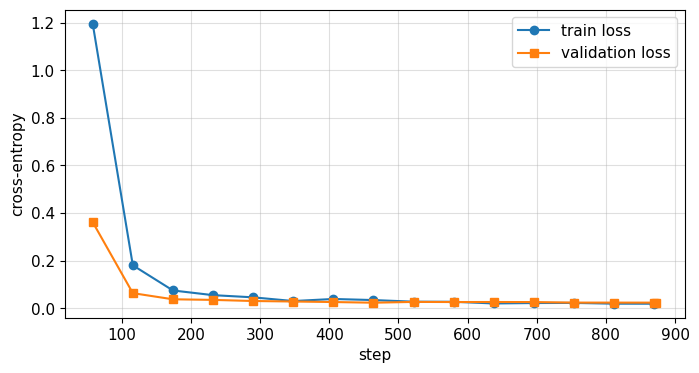

In [ ]:
set_seed(SEED)
model = make_model()
history, train_seconds = train_ner(model, tokenized['train'], tokenized['validation'])
RUN_TIMES['train_main_sec'] = train_seconds
train_curve = [(h['step'], h['loss']) for h in history if 'loss' in h]
eval_curve = [(h['step'], h['eval_loss']) for h in history if 'eval_loss' in h]
assert len(train_curve) >= 2 and len(eval_curve) >= 2, 'логируйте train и eval loss по ходу обучения'
print(f'обучение: {train_seconds:.1f} c на {DEVICE_NAME}, {len(tokenized["train"])} предложений, {EPOCHS} эпох(а)')

plt.figure(figsize=(8, 4))
plt.plot(*zip(*train_curve), 'o-', label='train loss')
plt.plot(*zip(*eval_curve), 's-', label='validation loss')
plt.xlabel('step')
plt.ylabel('cross-entropy')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

In [ ]:
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
steps_per_epoch = math.ceil(len(tokenized['train']) / BATCH_SIZE)
print(f'обучаемых параметров {trainable:,}, шагов {steps_per_epoch * EPOCHS} ({steps_per_epoch} на эпоху), '
      f'lr {LR}, batch {BATCH_SIZE}, warmup {WARMUP_SHARE:.0%}, fp16 {torch.cuda.is_available()}')
print(f'train loss: первый {train_curve[0][1]:.4f}, последний {train_curve[-1][1]:.4f}')
print(f'eval loss: минимум {min(v for _, v in eval_curve):.4f} на шаге {min(eval_curve, key=lambda x: x[1])[0]}, '
      f'последний {eval_curve[-1][1]:.4f}')
for epoch in range(1, EPOCHS + 1):
    points = [v for s, v in eval_curve if s <= epoch * steps_per_epoch]
    if points:
        print(f'eval loss к концу эпохи {epoch}: {points[-1]:.4f}')

обучаемых параметров 277,458,439, шагов 873 (291 на эпоху), lr 3e-05, batch 32, warmup 10%, fp16 True
train loss: первый 1.1954, последний 0.0189
eval loss: минимум 0.0232 на шаге 464, последний 0.0235
eval loss к концу эпохи 1: 0.0303
eval loss к концу эпохи 2: 0.0260
eval loss к концу эпохи 3: 0.0235


**Вопрос.** Почему выбраны такие гиперпараметры? Что видно на кривых: есть ли переобучение, нужно ли больше эпох? Сколько заняло обучение и на каком устройстве?

**Ответ:** Гиперпараметры: learning rate 3e-5 (стандартное значение для моделей такого размера), batch 32, 3 эпохи (873 шага), warmup 10% (первые шаги learning rate плавно растёт, чтобы не испортить предобученные веса), fp16 для ускорения.

По графикам: train loss упал с 1.195 до 0.019. Validation loss к концу первой эпохи 0.030, второй 0.026, третьей 0.0235, а минимум (0.0232) был уже в середине второй эпохи. Переобучения нет: validation loss не растёт. Но третья эпоха почти ничего не добавила, так что больше эпох не нужно.

Обучение заняло 198 секунд на Tesla T4.

## 4.2 Метрики (3 балла)

1. Посчитайте на validation и test отчет `seqeval` по типам (P/R/F1, support), micro и macro F1
2. Реализуйте `token_f1(gold, pred)` - micro-F1 по словам: верное срабатывание - слово, у которого предсказанный тег не `O` и совпадает с истинным; тег `O` в precision и recall не участвует; если не-`O` слов нет ни в gold, ни в pred, функция возвращает 0.0
3. Сравните токенный F1 и F1 по сущностям и объясните разницу

In [ ]:
def token_f1(gold, pred):
    tp = n_gold = n_pred = 0
    for gold_tags, pred_tags in zip(gold, pred):
        for g, p in zip(gold_tags, pred_tags):
            n_gold += g != 'O'
            n_pred += p != 'O'
            tp += p != 'O' and p == g
    if tp == 0:
        return 0.0
    precision, recall = tp / n_pred, tp / n_gold
    return 2 * precision * recall / (precision + recall)

===== validation
              precision    recall  f1-score   support

         LOC     0.9721    0.9846    0.9783      1168
         ORG     0.9279    0.9442    0.9360      1308
         PER     0.9903    0.9927    0.9915      1641

   micro avg     0.9651    0.9750    0.9700      4117
   macro avg     0.9634    0.9738    0.9686      4117
weighted avg     0.9653    0.9750    0.9701      4117

===== test
              precision    recall  f1-score   support

         LOC     0.9680    0.9779    0.9729      1175
         ORG     0.9276    0.9379    0.9327      1256
         PER     0.9892    0.9930    0.9911      1570

   micro avg     0.9636    0.9713    0.9674      4001
   macro avg     0.9616    0.9696    0.9656      4001
weighted avg     0.9636    0.9713    0.9674      4001

            F1 micro  F1 macro       P       R  token F1
val           0.9700    0.9686  0.9651  0.9750    0.9768
test          0.9674    0.9656  0.9636  0.9713    0.9771
baseline      0.5613  <- словарный бейз

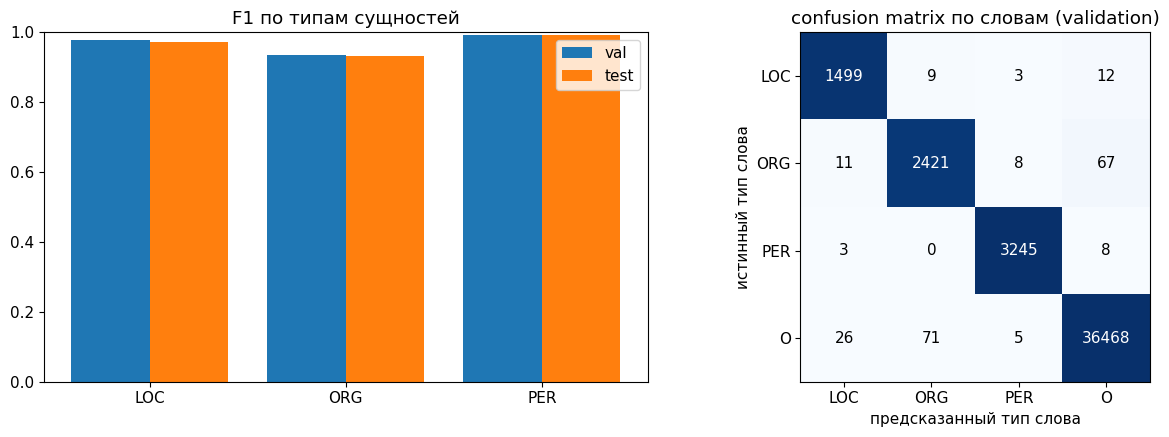

In [ ]:
g, p = [['B-PER', 'I-PER', 'O', 'B-LOC']], [['B-PER', 'O', 'O', 'B-LOC']]
assert abs(token_f1(g, p) - 0.8) < 1e-9                       # 2 верных слова из 2 предсказанных и 3 истинных
assert abs(f1_score(g, p) - 0.5) < 1e-9                       # а по сущностям верна одна из двух
assert token_f1([['O', 'O']], [['O', 'O']]) == 0.0 and token_f1(g, g) == 1.0

test_tokens = [list(ws) for ws in data['test']['tokens']]
test_gold = [to_tags(ids) for ids in data['test']['ner_tags']]
val_pred = predict_word_tags(model, val_tokens)
test_pred = predict_word_tags(model, test_tokens)


def per_type_report(gold, pred):
    report = classification_report(gold, pred, output_dict=True, zero_division=0)
    empty = {'precision': 0.0, 'recall': 0.0, 'f1-score': 0.0, 'support': 0}
    return {t: {k: float(report.get(t, empty)[k]) for k in empty} for t in ENTITY_TYPES}


def per_type_f1(gold, pred):
    return {t: r['f1-score'] for t, r in per_type_report(gold, pred).items()}


def full_metrics(gold, pred):
    per_type = per_type_report(gold, pred)
    return dict(**entity_scores(gold, pred), token_f1=token_f1(gold, pred), per_type=per_type)


final = full_metrics(test_gold, test_pred)
final_val = full_metrics(val_gold, val_pred)
for name, gold, pred in [('validation', val_gold, val_pred), ('test', test_gold, test_pred)]:
    print(f'===== {name}')
    print(classification_report(gold, pred, digits=4, zero_division=0))

print(f'{"":<10}{"F1 micro":>10}{"F1 macro":>10}{"P":>8}{"R":>8}{"token F1":>10}')
for name, m in [('val', final_val), ('test', final)]:
    print(f'{name:<10}{m["f1_micro"]:>10.4f}{m["f1_macro"]:>10.4f}{m["precision"]:>8.4f}{m["recall"]:>8.4f}{m["token_f1"]:>10.4f}')
print(f'{"baseline":<10}{baseline["majority"]["f1_micro"]:>10.4f}  <- словарный бейзлайн на val')

word_types = ENTITY_TYPES + ['O']
confusion = np.zeros((len(word_types), len(word_types)), dtype=int)
for gold_tags, pred_tags in zip(val_gold, val_pred):
    for g, p in zip(gold_tags, pred_tags):
        confusion[word_types.index(g[2:] if g != 'O' else 'O'), word_types.index(p[2:] if p != 'O' else 'O')] += 1
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
x = np.arange(len(ENTITY_TYPES))
for k, (name, m) in enumerate([('val', final_val), ('test', final)]):
    axes[0].bar(x + (k - 0.5) * 0.4, [m['per_type'][t]['f1-score'] for t in ENTITY_TYPES], 0.4, label=name)
axes[0].set_xticks(x, ENTITY_TYPES)
axes[0].set_ylim(0, 1)
axes[0].set_title('F1 по типам сущностей')
axes[0].legend()
norm = confusion / confusion.sum(1, keepdims=True)
axes[1].imshow(norm, cmap='Blues', vmin=0, vmax=1)
for i in range(len(word_types)):
    for j in range(len(word_types)):
        axes[1].text(j, i, confusion[i, j], ha='center', va='center', color='white' if norm[i, j] > 0.5 else 'black')
axes[1].set_xticks(range(len(word_types)), word_types)
axes[1].set_yticks(range(len(word_types)), word_types)
axes[1].set_xlabel('предсказанный тип слова')
axes[1].set_ylabel('истинный тип слова')
axes[1].set_title('confusion matrix по словам (validation)')
plt.tight_layout()
plt.show()

**Вопрос.** Какой тип сущностей распознается хуже всего и почему (частота, длина спанов, разнообразие)? Чем отличаются micro и macro F1 в вашем случае? Чем отличаются токенный F1 и F1 по сущностям в ваших числах и за счет чего (какой выше и почему)? Какой из них ближе к тому, что нужно пользователю NER?

**Ответ:** На test F1 по сущностям = 0.967 (precision 0.964, recall 0.971), macro F1 = 0.966. Словарный бейзлайн давал 0.561.

Лучше всего модель находит людей (PER 0.991), чуть хуже места (LOC 0.973), хуже всего организации (ORG 0.933). Названия организаций длинные, часто в кавычках и содержат внутри другие сущности («ГУ МВД по Кемеровской области»), поэтому модель ошибается в их границах. По confusion matrix видно, что слова ORG чаще всего путаются с `O`: модель то отрезает часть названия, то добавляет лишнее слово.

Micro и macro почти равны, потому что типов примерно поровну.

Токенный F1 (0.977) выше, чем F1 по сущностям (0.967), потому что он засчитывает правильные отдельные слова, даже если граница сущности неверная. Для пользователя важнее F1 по сущностям: ему нужна вся сущность целиком («Министерство иностранных дел», а не одно «Министерство»).

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

Аналог разбора ошибок детектора по IoU. Реализуйте `categorize_errors(gold_spans, pred_spans)`: каждый истинный спан получает ровно одну категорию, предсказанный спан, не пересекающийся ни с одним истинным, - категорию `spurious`. Возвращается список `(категория, истинный спан или None, предсказанный спан или None)`:

- `correct` - есть предсказанный спан с теми же границами и типом
- `boundary` - точного совпадения нет, но есть пересекающийся предсказанный спан того же типа (ошибка границы, аналог ошибки локализации)
- `type` - пересекающегося спана того же типа нет, но есть пересекающийся спан другого типа (ошибка типа, аналог ошибки класса)
- `missed` - ни один предсказанный спан не пересекается с истинным (пропуск)
- `spurious` - лишний спан (ложное срабатывание)

Посчитайте категории на validation, доли среди ошибок, покажите 5+ примеров ошибок разных категорий глазами (предложение, истинный и предсказанный спаны).

In [ ]:
ERROR_CATEGORIES = ['correct', 'boundary', 'type', 'missed', 'spurious']


def overlap(a, b):
    return min(a[1], b[1]) - max(a[0], b[0])


def categorize_errors(gold_spans, pred_spans):
    gold_spans = [tuple(s) for s in gold_spans]
    pred_spans = [tuple(s) for s in pred_spans]
    result = []
    for g in gold_spans:
        touching = sorted((p for p in pred_spans if overlap(g, p) > 0), key=lambda p: -overlap(g, p))
        same_type = [p for p in touching if p[2] == g[2]]
        if g in pred_spans:
            result.append(('correct', g, g))
        elif same_type:
            result.append(('boundary', g, same_type[0]))
        elif touching:
            result.append(('type', g, touching[0]))
        else:
            result.append(('missed', g, None))
    for p in pred_spans:
        if not any(overlap(g, p) > 0 for g in gold_spans):
            result.append(('spurious', None, p))
    return result

истинных спанов 4117, ошибок 155
correct     4014
boundary      65   41.9% ошибок
type          20   12.9% ошибок
missed        18   11.6% ошибок
spurious      52   33.5% ошибок

тип      correct  boundary      type    missed  spurious
LOC         1150         4        10         4        16
ORG         1235        56         7        10        31
PER         1629         5         3         4         5


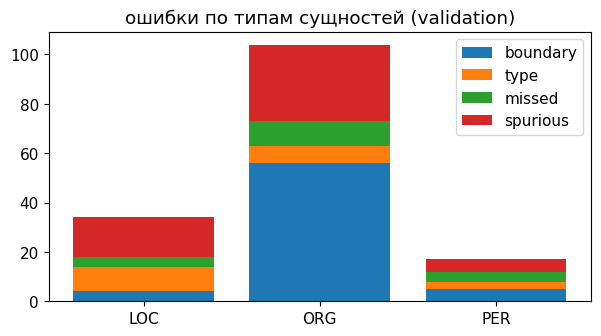


===== boundary: 65
#1591: ...Читайте также : В Румынии Конституционный ⟦суд⟧ поддержал импичмент Президенту...
      gold [суд]ORG   pred [Конституционный суд]ORG
#1739: ...Кудрявец генеральным директором закрытого акционерного общества ⟦" Белорусская калийная компания "⟧ - на этой должности она сменила...
      gold [" Белорусская калийная компания "]ORG   pred [Белорусская калийная компания]ORG
#117: ...) одной из крупнейших страховых компаний ⟦Азии AIA Group⟧ , а до этого ушел со...
      gold [Азии AIA Group]ORG   pred [AIA Group]ORG
#926: ..., заявил , что председателя фракции ⟦" ГП "⟧ в муниципалитете Ярослава Юдина не было...
      gold [" ГП "]ORG   pred [ГП]ORG

===== type: 20
#1997: ...Всего ⟦Евросоюз⟧ и МВФ согласились предоставить Греции 110...
      gold [Евросоюз]LOC   pred [Евросоюз]ORG
#1721: ...на улицах республиканской столицы Черкесска при ⟦Ахметханове⟧ наконец стали регулярно работать патрули ГИБДД...
      gold [Ахметханове]PER   pred [Ахметханове]LOC
#1557: ...по

In [ ]:
gold = [(0, 2, 'PER'), (4, 5, 'LOC'), (7, 9, 'ORG'), (11, 12, 'PER')]
pred = [(0, 2, 'PER'), (4, 6, 'LOC'), (7, 9, 'LOC'), (13, 14, 'ORG')]
res = categorize_errors(gold, pred)
assert collections.Counter(c for c, _, _ in res) == {'correct': 1, 'boundary': 1, 'type': 1, 'missed': 1, 'spurious': 1}
assert ('type', (7, 9, 'ORG'), (7, 9, 'LOC')) in res and ('spurious', None, (13, 14, 'ORG')) in res
assert ('boundary', (4, 5, 'LOC'), (4, 6, 'LOC')) in res and ('missed', (11, 12, 'PER'), None) in res
assert categorize_errors([], []) == [] and categorize_errors([], [(0, 1, 'PER')]) == [('spurious', None, (0, 1, 'PER'))]
assert [c for c, _, _ in categorize_errors([(0, 3, 'LOC')], [(1, 2, 'PER'), (2, 3, 'LOC')])] == ['boundary']
assert [c for c, _, _ in categorize_errors([(0, 2, 'LOC'), (2, 4, 'LOC')], [(0, 4, 'LOC')])] == ['boundary', 'boundary']
assert sorted(c for c, _, _ in categorize_errors([(0, 2, 'PER')], [(2, 3, 'PER')])) == ['missed', 'spurious']   # end не включается: спаны только соприкасаются

counts = collections.Counter()
by_type = collections.defaultdict(collections.Counter)
examples = collections.defaultdict(list)
for i, (gold_tags, pred_tags) in enumerate(zip(val_gold, val_pred)):
    for category, g, p in categorize_errors(bio_to_spans(gold_tags), bio_to_spans(pred_tags)):
        counts[category] += 1
        by_type[(g or p)[2]][category] += 1
        if category != 'correct':
            examples[category].append((i, g, p))
errors = {c: counts[c] for c in ERROR_CATEGORIES}
n_errors = sum(v for c, v in errors.items() if c != 'correct')

print(f'истинных спанов {sum(v for c, v in errors.items() if c != "spurious")}, ошибок {n_errors}')
for c in ERROR_CATEGORIES:
    share = '' if c == 'correct' else f'   {errors[c] / max(n_errors, 1):.1%} ошибок'
    print(f'{c:<10}{errors[c]:>6}{share}')
print(f'\n{"тип":<6}' + ''.join(f'{c:>10}' for c in ERROR_CATEGORIES))
for t in ENTITY_TYPES:
    print(f'{t:<6}' + ''.join(f'{by_type[t][c]:>10}' for c in ERROR_CATEGORIES))

plt.figure(figsize=(7, 3.5))
bottom = np.zeros(len(ENTITY_TYPES))
for c in ERROR_CATEGORIES[1:]:
    v = np.array([by_type[t][c] for t in ENTITY_TYPES])
    plt.bar(ENTITY_TYPES, v, bottom=bottom, label=c)
    bottom += v
plt.title('ошибки по типам сущностей (validation)')
plt.legend()
plt.show()


def show_span(words, span):
    return 'нет' if span is None else f'[{" ".join(words[span[0]:span[1]])}]{span[2]}'


def show_example(i, g, p, width=6):
    words = val_tokens[i]
    spans = [s for s in (g, p) if s is not None]
    lo, hi = max(0, min(s[0] for s in spans) - width), max(s[1] for s in spans) + width
    marked = []
    for k in range(lo, min(hi, len(words))):
        word = words[k]
        if g is not None and k == g[0]:
            word = '⟦' + word
        if g is not None and k == g[1] - 1:
            word = word + '⟧'
        marked.append(word)
    return f'#{i}: ...{" ".join(marked)}...\n      gold {show_span(words, g)}   pred {show_span(words, p)}'


rng = random.Random(SEED)
for c in ERROR_CATEGORIES[1:]:
    print(f'\n===== {c}: {len(examples[c])}')
    for i, g, p in rng.sample(examples[c], min(4, len(examples[c]))):
        print(show_example(i, g, p))

**Вопрос.** Какая категория ошибок самая частая? Что общего у примеров в каждой категории? Какие ошибки - на самом деле ошибки разметки, а не модели? Что бы вы сделали, чтобы уменьшить самую частую категорию?

**Ответ:** На validation модель нашла точно 4014 сущностей из 4117, всего ошибок 155:
- ошибки границы: 65 (42%), почти все у ORG (56);
- лишние сущности: 52 (34%);
- перепутан тип: 20 (13%);
- пропущены: 18 (12%).

Многие ошибки на самом деле ошибки разметки датасета, а не модели. Например, в разметке «Конституционный суд» отмечено только как «суд», а модель взяла название целиком. Кавычки в названиях иногда входят в сущность, иногда нет. Среди «лишних» сущностей модели много настоящих, которые просто забыли разметить: «Кремля», «Пулковского шоссе», «LPN».

Настоящие ошибки модели — путаница типа на редких словах: фамилия «Ахметханове» → место, город «Доху» → человек, агентство «Киодо» → место. Почти все пропуски из одного очень длинного предложения (#1239), которое, скорее всего, обрезано по лимиту длины.

Как уменьшить ошибки границы: сначала сделать разметку единообразной (например, кавычки в названиях всегда включать или всегда не включать), а потом добавить ограничения на последовательность BIO-тегов (CRF). Для длинных предложений — обрабатывать их частями, а не обрезать.

## 5.2 Абляция (1 балл)

Один дополнительный эксперимент на выбор, все остальное как в 4.1:

- `'freeze'` - замороженный энкодер (учится только голова) vs полное дообучение. Сравните F1, время и число обучаемых параметров
- `'all_subwords'` - метка на все сабворды (`data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names, fn_kwargs=dict(label_all_subwords=True))`) vs только на первый. Оценка по-прежнему по словам через `predict_word_tags`

Результат положите в `ablation` - словарь с настройкой и метриками обоих вариантов.

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'loss': '1.214', 'grad_norm': '2.645', 'learning_rate': '1.966e-05', 'epoch': '0.1993'}
{'eval_loss': '0.3355', 'eval_runtime': '2.589', 'eval_samples_per_second': '831.6', 'eval_steps_per_second': '13.13', 'epoch': '0.1993'}
{'loss': '0.1685', 'grad_norm': '6.092', 'learning_rate': '2.893e-05', 'epoch': '0.3986'}
{'eval_loss': '0.05861', 'eval_runtime': '2.663', 'eval_samples_per_second': '808.4', 'eval_steps_per_second': '12.77', 'epoch': '0.3986'}
{'loss': '0.07476', 'grad_norm': '4.232', 'learning_rate': '2.672e-05', 'epoch': '0.5979'}
{'eval_loss': '0.03984', 'eval_runtime': '2.661', 'eval_samples_per_second': '809.2', 'eval_steps_per_second': '12.78', 'epoch': '0.5979'}
{'loss': '0.056', 'grad_norm': '1.815', 'learning_rate': '2.45e-05', 'epoch': '0.7973'}
{'eval_loss': '0.04834', 'eval_runtime': '2.633', 'eval_samples_per_second': '817.7', 'eval_steps_per_second': '12.91', 'epoch': '0.7973'}
{'loss': '0.04993', 'grad_norm': '2.587', 'learning_rate': '2.229e-05', 'epoch': '0.996

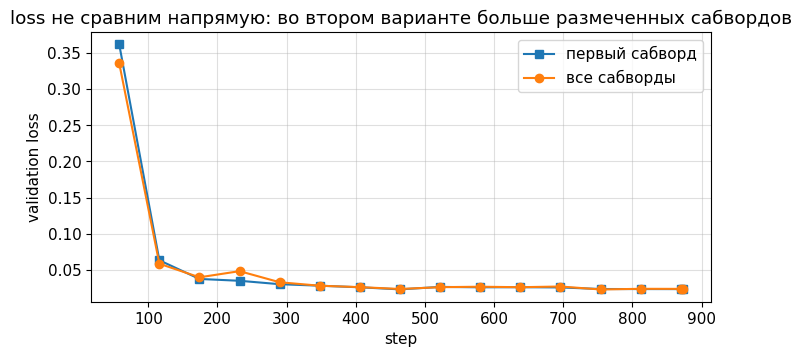

In [ ]:
ABLATION = 'all_subwords'   # 'freeze' или 'all_subwords'

tokenized_all = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names,
                         fn_kwargs=dict(label_all_subwords=True))


def n_labeled(ds):
    return sum(sum(l != -100 for l in labels) for labels in ds['labels'])


set_seed(SEED)
model_all = make_model()
history_all, seconds_all = train_ner(model_all, tokenized_all['train'], tokenized_all['validation'], out_dir='runs/all_subwords')
RUN_TIMES['train_all_subwords_sec'] = seconds_all
pred_all = predict_word_tags(model_all, val_tokens)
del model_all
if device.type == 'cuda':
    torch.cuda.empty_cache()


def short_metrics(gold, pred):
    return dict(**entity_scores(gold, pred), token_f1=token_f1(gold, pred),
                per_type_f1=per_type_f1(gold, pred))


ablation = dict(
    setting=ABLATION, split='validation',
    first_subword=dict(**short_metrics(val_gold, val_pred), train_sec=train_seconds, labeled_subwords=n_labeled(tokenized['train'])),
    all_subwords=dict(**short_metrics(val_gold, pred_all), train_sec=seconds_all, labeled_subwords=n_labeled(tokenized_all['train'])),
)
print(f'{"":<15}{"F1 micro":>10}{"F1 macro":>10}{"P":>8}{"R":>8}{"token F1":>10}{"время, с":>10}{"меток в train":>15}')
for name in ('first_subword', 'all_subwords'):
    m = ablation[name]
    print(f'{name:<15}{m["f1_micro"]:>10.4f}{m["f1_macro"]:>10.4f}{m["precision"]:>8.4f}{m["recall"]:>8.4f}'
          f'{m["token_f1"]:>10.4f}{m["train_sec"]:>10.0f}{m["labeled_subwords"]:>15,}')
for t in ENTITY_TYPES:
    print(f'  F1 {t}: {ablation["first_subword"]["per_type_f1"][t]:.4f} -> {ablation["all_subwords"]["per_type_f1"][t]:.4f}')
diff = [i for i, (a, b) in enumerate(zip(val_pred, pred_all)) if a != b]
print(f'предложений validation, где предсказания различаются: {len(diff)} из {len(val_pred)}')

eval_all = [(h['step'], h['eval_loss']) for h in history_all if 'eval_loss' in h]
plt.figure(figsize=(8, 3.5))
plt.plot(*zip(*eval_curve), 's-', label='первый сабворд')
plt.plot(*zip(*eval_all), 'o-', label='все сабворды')
plt.xlabel('step')
plt.ylabel('validation loss')
plt.title('loss не сравним напрямую: во втором варианте больше размеченных сабвордов')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Насколько изменилась метрика и время? Чем вы объясняете результат? Что бы вы проверили следующим шагом, чтобы вывод был надежнее?

**Ответ:** Сравнила два варианта: метка только на первой части слова (как в основном обучении) и метка на всех частях слова. Всё остальное одинаково.

Результат на validation: 0.9700 → 0.9725 (+0.0025), прибавка в основном на ORG (0.936 → 0.944). Время обучения почти одинаковое (198 и 191 с).

Но эта разница очень маленькая. Я запускала ноутбук несколько раз, и разница выходила от −0.0005 до +0.0036, то есть она того же размера, что и случайный разброс между запусками. Правда, в 3 из 4 запусков она была положительной и почти всегда за счёт ORG. Это логично: в длинных названиях организаций много слов, которые делятся на части, и разметка всех частей даёт модели больше информации.

Чтобы вывод был надёжным, нужно повторить оба варианта с несколькими разными seed и сравнить средние.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, главные ограничения (данные, разметка, модель, бюджет), что бы вы сделали дальше.

**Ответ:** Дообученная `xlm-roberta-base` даёт на test F1 = 0.967. Словарный бейзлайн дал 0.561, а модель без обучения 0.027. Обучение заняло всего 198 секунд.

Лучше всего модель распознаёт людей (0.991), хуже всего организации (0.933). Главная проблема — границы названий организаций, и часть этих «ошибок» на самом деле неаккуратная разметка датасета.

Метка на все части слова почти ничего не дала: разница в пределах случайного разброса. Маленькая rubert-tiny2 хуже на 4 пункта, зато в 6 раз быстрее. Модель сильно зависит от заглавных букв: на тексте в нижнем регистре F1 падает до 0.40. Перевод в fp16 ускоряет модель в 4.5 раза без потери качества.

Ограничения: каждый эксперимент запускался с одним seed (а между повторными запусками F1 менялся от 0.967 до 0.970); все данные из одного источника; модель видит только одно предложение.

Что дальше: почистить разметку организаций, добавить в обучение тексты с изменённым регистром, повторить эксперименты с несколькими seed и проверить модель на текстах другого типа (например, из соцсетей).

### Сохранение результатов

Ячейка сохраняет `artifacts/metrics.json`. Выполняется и в `FAST_MODE` для проверки формата, при финальном прогоне перезаписывается с `fast_mode: false`. Сдайте файл вместе с ноутбуком.

In [ ]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


metrics = dict(
    track='nlp', model=MODEL_ID, revision=REVISION,
    dataset=f'{DATASET_ID}/{DATASET_CONFIG}' if DATASET_CONFIG else str(DATASET_ID), classes=ENTITY_TYPES,
    n_train=len(data['train']), n_val=len(data['validation']), n_test=len(data['test']),
    params_total=sum(p.numel() for p in model.parameters()),
    baseline=baseline, final=final, ablation=ablation, errors=errors,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES.get('train_main_sec'), fast_mode=FAST_MODE)
for key in ['f1_micro', 'f1_macro', 'precision', 'recall', 'token_f1', 'per_type']:
    assert key in final, f'в final нет {key}'
(ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(json_ready({k: v for k, v in metrics.items() if k not in ('final', 'baseline')}), ensure_ascii=False)[:600])
print('final F1 micro', round(final['f1_micro'], 4))

{"track": "nlp", "model": "FacebookAI/xlm-roberta-base", "revision": "e73636d4f797dec63c3081bb6ed5c7b0bb3f2089", "dataset": "RCC-MSU/collection3", "classes": ["LOC", "ORG", "PER"], "n_train": 9301, "n_val": 2153, "n_test": 1922, "params_total": 277458439, "ablation": {"setting": "all_subwords", "split": "validation", "first_subword": {"f1_micro": 0.9700338327694539, "f1_macro": 0.9685822321064018, "precision": 0.9651358499639336, "recall": 0.974981782851591, "token_f1": 0.9767601288818812, "per_type_f1": {"LOC": 0.9783071033602723, "ORG": 0.9359605911330049, "PER": 0.9914790018259282}, "train_
final F1 micro 0.9674


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за бонусы суммарно - до 4 баллов из 5.5 предложенных.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых предложений (Label Studio, doccano или вручную в JSON): например, тексты из другого источника или трудные случаи из 5.1. Опишите инструкцию разметки, приведите разметку к контракту из 2.1, добавьте в train (или сделайте отдельный test) и покажите, как изменилась метрика. Файл с разметкой приложите к сдаче.

In [ ]:
BONUS_RESULTS = {}
if '6.1' in BONUS_TASKS:
    pass

**Вопрос.** Сколько и каких примеров вы разметили, сколько времени заняла разметка, как изменилась метрика и на каком сплите? Где вы сами сомневались в разметке?

**Ответ:**

## 6.2 Другая модель (1 балл)

Сравните с другим энкодером (многоязычный vs одноязычный, base vs маленький) при том же протоколе - или zero-shot NER открытой LLM с Hugging Face против дообученного энкодера. Сравните F1, время обучения и инференса, размер.

In [ ]:
if '6.2' in BONUS_TASKS:
    MODEL_ID_2 = 'cointegrated/rubert-tiny2'
    REVISION_2 = 'e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae'
    LR_2 = 2e-4
    tokenizer_2 = AutoTokenizer.from_pretrained(MODEL_ID_2, revision=REVISION_2)
    tokenized_2 = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names,
                           fn_kwargs=dict(tok=tokenizer_2))
    set_seed(SEED)
    model_2 = make_model(MODEL_ID_2, REVISION_2)
    history_2, seconds_2 = train_ner(model_2, tokenized_2['train'], tokenized_2['validation'], lr=LR_2,
                                     tok=tokenizer_2, out_dir='runs/rubert_tiny2')
    RUN_TIMES['train_rubert_tiny2_sec'] = seconds_2

    def timed_predict(m, tok):
        predict_word_tags(m, test_tokens[:64], tok=tok)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        start = time.perf_counter()
        preds = predict_word_tags(m, test_tokens, tok=tok)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        return preds, time.perf_counter() - start

    def subwords_per_word(tok):
        enc = tok(val_tokens, is_split_into_words=True)
        n_sub = sum(len([w for w in enc.word_ids(i) if w is not None]) for i in range(len(val_tokens)))
        return n_sub / sum(len(ws) for ws in val_tokens)

    compare = {}
    for name, m, tok, seconds in [(MODEL_ID, model, tokenizer, train_seconds), (MODEL_ID_2, model_2, tokenizer_2, seconds_2)]:
        test_pred_m, infer_sec = timed_predict(m, tok)
        compare[name] = dict(params=n_params(m), size_mb=n_params(m) * 4 / 2**20, train_sec=seconds,
                             infer_test_sec=infer_sec, subwords_per_word=subwords_per_word(tok),
                             val_f1=f1_score(val_gold, predict_word_tags(m, val_tokens, tok=tok), zero_division=0),
                             test_f1=f1_score(test_gold, test_pred_m, zero_division=0),
                             test_f1_macro=f1_score(test_gold, test_pred_m, average='macro', zero_division=0))
    print(f'{"модель":<30}{"параметры":>13}{"МБ fp32":>9}{"обучение, с":>13}{"инференс test, с":>18}'
          f'{"сабв./слово":>13}{"F1 val":>8}{"F1 test":>9}{"macro test":>12}')
    for name, r in compare.items():
        print(f'{name:<30}{r["params"]:>13,}{r["size_mb"]:>9.0f}{r["train_sec"]:>13.0f}{r["infer_test_sec"]:>18.2f}'
              f'{r["subwords_per_word"]:>13.2f}{r["val_f1"]:>8.4f}{r["test_f1"]:>9.4f}{r["test_f1_macro"]:>12.4f}')
    BONUS_RESULTS['6.2'] = dict(models=compare, lr={MODEL_ID: LR, MODEL_ID_2: LR_2}, epochs=EPOCHS, batch_size=BATCH_SIZE)
    del model_2
    if device.type == 'cuda':
        torch.cuda.empty_cache()

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'loss': '0.9355', 'grad_norm': '0.854', 'learning_rate': '0.000131', 'epoch': '0.1993'}
{'eval_loss': '0.2751', 'eval_runtime': '0.5127', 'eval_samples_per_second': '4199', 'eval_steps_per_second': '66.31', 'epoch': '0.1993'}
{'loss': '0.1855', 'grad_norm': '1.611', 'learning_rate': '0.0001929', 'epoch': '0.3986'}
{'eval_loss': '0.1012', 'eval_runtime': '0.5154', 'eval_samples_per_second': '4178', 'eval_steps_per_second': '65.97', 'epoch': '0.3986'}
{'loss': '0.104', 'grad_norm': '1.613', 'learning_rate': '0.0001781', 'epoch': '0.5979'}
{'eval_loss': '0.07146', 'eval_runtime': '0.5269', 'eval_samples_per_second': '4086', 'eval_steps_per_second': '64.53', 'epoch': '0.5979'}
{'loss': '0.08185', 'grad_norm': '0.871', 'learning_rate': '0.0001634', 'epoch': '0.7973'}
{'eval_loss': '0.05935', 'eval_runtime': '0.7504', 'eval_samples_per_second': '2869', 'eval_steps_per_second': '45.31', 'epoch': '0.7973'}
{'loss': '0.07016', 'grad_norm': '0.8338', 'learning_rate': '0.0001486', 'epoch': '0.99

**Вопрос.** Что лучше и какой ценой (время, память)? Как вы обеспечили честность сравнения?

**Ответ:** XLM-R лучше по качеству: F1 на test 0.967 против 0.929 у rubert-tiny2 (+3.8 пункта). Зато она намного тяжелее: в 9.5 раз больше параметров (277M против 29M), обучается в 6 раз дольше (198 с против 33 с) и предсказывает в 3 раза медленнее (3.4 с против 1.1 с на весь test).

Интересно, что rubert-tiny2 делит русские слова на меньшее число частей (1.14 на слово против 1.61): её словарь создан специально для русского языка.

Сравнение честное: одинаковые данные, seed, число эпох, batch, длина и одна и та же оценка. Learning rate у каждой модели свой, стандартный для её размера, по test ничего не подбиралось.

Вывод: если нужна скорость, хватит rubert-tiny2 (F1 0.93), если важно качество — XLM-R.

## 6.3 Устойчивость к сдвигу (1 балл)

Испортите validation и посмотрите на F1: опечатки, весь текст в нижнем или верхнем регистре, транслит, или другой домен (новости, соцсети, другой датасет с теми же типами). Метки при порче не меняются.

порча            F1       P       R   F1 LOC   F1 ORG   F1 PER  сабв./слово
clean        0.9700  0.9651  0.9750   0.9783   0.9360   0.9915         1.61
lower        0.4033  0.8003  0.2696   0.1136   0.1131   0.6863         1.65
upper        0.7491  0.7674  0.7316   0.7291   0.6132   0.8655         3.03
typos_30%    0.9206  0.9173  0.9240   0.9185   0.8981   0.9398         1.90
translit     0.8372  0.8255  0.8492   0.8222   0.7796   0.8898         2.23
  clean: Обама назначил послов США в Грузии и Таджикистане
  lower: обама назначил послов сша в грузии и таджикистане
  upper: ОБАМА НАЗНАЧИЛ ПОСЛОВ США В ГРУЗИИ И ТАДЖИКИСТАНЕ
  typos_30%: Обама назначил послов США в Грузии и Таджикистане
  translit: Obama naznachil poslov SShA v Gruzii i Tadzhikistane


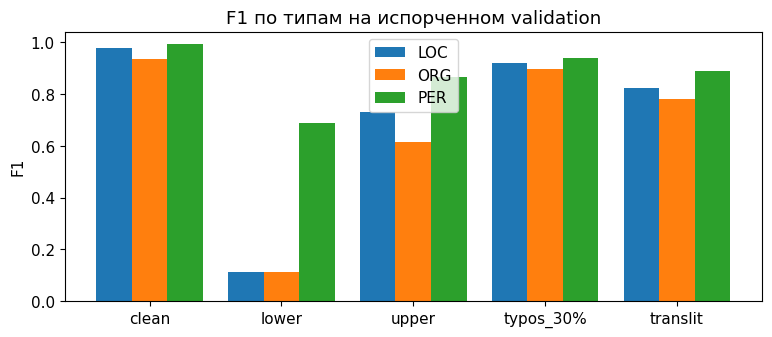

In [ ]:
if '6.3' in BONUS_TASKS:
    TRANSLIT = dict(zip('абвгдеёжзийклмнопрстуфхцчшщъыьэюя',
                        ['a', 'b', 'v', 'g', 'd', 'e', 'e', 'zh', 'z', 'i', 'y', 'k', 'l', 'm', 'n', 'o', 'p', 'r', 's',
                         't', 'u', 'f', 'kh', 'ts', 'ch', 'sh', 'shch', '', 'y', '', 'e', 'yu', 'ya']))

    def translit(word):
        out = []
        for ch in word:
            latin = TRANSLIT.get(ch.lower(), ch)
            out.append(latin.capitalize() if ch.isupper() else latin)
        return ''.join(out) or word

    def typo(word, rng):
        if len(word) < 4 or rng.random() > 0.3:
            return word
        i = rng.randrange(len(word) - 1)
        return word[:i] + word[i + 1] + word[i] + word[i + 2:]

    rng = random.Random(SEED)
    corruptions = {
        'clean': lambda ws: ws,
        'lower': lambda ws: [w.lower() for w in ws],
        'upper': lambda ws: [w.upper() for w in ws],
        'typos_30%': lambda ws: [typo(w, rng) for w in ws],
        'translit': lambda ws: [translit(w) for w in ws],
    }
    shift = {}
    for name, fn in corruptions.items():
        tokens_c = [fn(list(ws)) for ws in val_tokens]
        pred_c = predict_word_tags(model, tokens_c)
        enc_c = tokenizer(tokens_c, is_split_into_words=True)
        n_sub = sum(len([w for w in enc_c.word_ids(i) if w is not None]) for i in range(len(tokens_c)))
        shift[name] = dict(**entity_scores(val_gold, pred_c),
                           per_type_f1=per_type_f1(val_gold, pred_c),
                           subwords_per_word=n_sub / sum(len(ws) for ws in tokens_c),
                           example=' '.join(tokens_c[0][:12]))
    print(f'{"порча":<11}{"F1":>8}{"P":>8}{"R":>8}' + ''.join(f'{"F1 " + t:>9}' for t in ENTITY_TYPES) + f'{"сабв./слово":>13}')
    for name, r in shift.items():
        print(f'{name:<11}{r["f1_micro"]:>8.4f}{r["precision"]:>8.4f}{r["recall"]:>8.4f}'
              + ''.join(f'{r["per_type_f1"][t]:>9.4f}' for t in ENTITY_TYPES) + f'{r["subwords_per_word"]:>13.2f}')
    for name, r in shift.items():
        print(f'  {name}: {r["example"]}')
    plt.figure(figsize=(9, 3.5))
    x = np.arange(len(shift))
    for k, t in enumerate(ENTITY_TYPES):
        plt.bar(x + (k - 1) * 0.27, [r['per_type_f1'][t] for r in shift.values()], 0.27, label=t)
    plt.xticks(x, list(shift))
    plt.ylabel('F1')
    plt.title('F1 по типам на испорченном validation')
    plt.legend()
    plt.show()
    BONUS_RESULTS['6.3'] = {k: {kk: vv for kk, vv in v.items() if kk != 'example'} for k, v in shift.items()}

**Вопрос.** Какая порча сильнее всего роняет F1 и почему (вспомните, как токенизатор режет слова и какие признаки сущности есть в тексте)?

**Ответ:** Сильнее всего качество падает, если перевести текст в нижний регистр: F1 0.970 → 0.403. Модель почти перестаёт находить сущности (recall падает до 0.27), но то, что находит, обычно верно (precision 0.80). Значит, модель сильно опирается на заглавные буквы: в русском языке это главный признак имени собственного. Хуже всего с местами (LOC 0.11) и организациями (ORG 0.11). Людей модель всё ещё неплохо находит (PER 0.69) по контексту («заявил», «министр») и по виду фамилий.

Верхний регистр даёт 0.749: заглавные буквы теперь у всех слов, а слова КАПСОМ модель видела редко и делит их на много мелких частей. Транслит даёт 0.837: латиницу модель знает, но русские слова латиницей ей непривычны. Опечатки влияют меньше всего (0.921): контекст помогает понять слово.

Улучшить можно, если при обучении показывать модели и такие «испорченные» тексты.

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте модель в ONNX (или примените `torch.compile` / квантизацию), замерьте задержку до и после на одном и том же батче и устройстве (с прогревом, среднее по 10+ запускам) и проверьте, что F1 не упал (или упал незначительно).

Для ONNX: `%pip install -q onnx onnxruntime onnxscript`.

In [ ]:
if '6.4' in BONUS_TASKS:
    fast_dtype = torch.float16 if device.type == 'cuda' else torch.bfloat16
    bench = tokenizer(val_tokens[:32], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH,
                      padding='max_length', return_tensors='pt')
    bench = {k: v.to(device) for k, v in bench.items()}

    model_fp32 = make_model()
    model_fp32.load_state_dict(model.state_dict())
    model_fp32.eval().to(device)
    model_half = copy.deepcopy(model_fp32).to(fast_dtype)
    print('forward основной модели после Trainer обернут в autocast:', 'forward' in vars(model))

    def latency_ms(m, autocast=False, runs=20):
        m.eval().to(device)
        with torch.inference_mode(), torch.autocast(device.type, dtype=fast_dtype, enabled=autocast):
            for _ in range(3):
                m(**bench)
            if device.type == 'cuda':
                torch.cuda.synchronize()
            start = time.perf_counter()
            for _ in range(runs):
                m(**bench)
            if device.type == 'cuda':
                torch.cuda.synchronize()
        return (time.perf_counter() - start) / runs * 1000

    def predict(m, autocast=False):
        with torch.autocast(device.type, dtype=fast_dtype, enabled=autocast):
            return predict_word_tags(m, val_tokens)

    half_name = str(fast_dtype).replace('torch.', '')
    variants = [('fp32', model_fp32, False), (f'autocast {half_name}', model_fp32, True), (half_name, model_half, False)]
    speed = {}
    for name, m, autocast in variants:
        pred_m = predict(m, autocast)
        speed[name] = dict(latency_ms=latency_ms(m, autocast),
                           size_mb=sum(p.numel() * p.element_size() for p in m.parameters()) / 2**20,
                           val_f1=f1_score(val_gold, pred_m, zero_division=0),
                           changed_sentences=sum(a != b for a, b in zip(pred_m, val_pred)))
    print(f'устройство {DEVICE_NAME}, батч 32 x {MAX_LENGTH} сабвордов, среднее по 20 прогонам после прогрева')
    base = speed['fp32']['latency_ms']
    for name, r in speed.items():
        print(f'{name:<18} {r["latency_ms"]:8.1f} мс  x{base / r["latency_ms"]:.2f}   {r["size_mb"]:6.0f} МБ   '
              f'F1 val {r["val_f1"]:.4f} ({r["val_f1"] - speed["fp32"]["val_f1"]:+.4f})   '
              f'предложений с другими тегами: {r["changed_sentences"]}')
    BONUS_RESULTS['6.4'] = dict(device=DEVICE_NAME, batch=[32, MAX_LENGTH], results=speed)
    del model_fp32, model_half
    if device.type == 'cuda':
        torch.cuda.empty_cache()

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

forward основной модели после Trainer обернут в autocast: True
устройство Tesla T4, батч 32 x 128 сабвордов, среднее по 20 прогонам после прогрева
fp32                  191.3 мс  x1.00     1058 МБ   F1 val 0.9700 (+0.0000)   предложений с другими тегами: 0
autocast float16       49.1 мс  x3.90     1058 МБ   F1 val 0.9700 (+0.0000)   предложений с другими тегами: 0
float16                42.3 мс  x4.52      529 МБ   F1 val 0.9700 (+0.0000)   предложений с другими тегами: 0


**Вопрос.** Какое ускорение и на каком устройстве? Изменилась ли метрика? Почему выигрыш зависит от модели (вспомните, где у вашей модели основная часть параметров и вычислений)?

**Ответ:** Замерила время на батче 32 предложения × 128 токенов на T4:
- fp32: 191 мс;
- autocast fp16: 49 мс (в 3.9 раза быстрее);
- чистый fp16: 42 мс (в 4.5 раза быстрее).

Модель в fp16 занимает в 2 раза меньше памяти (529 МБ вместо 1058), а качество не изменилось совсем (F1 0.9700, ни один тег не поменялся). Ускорение даёт то, что видеокарта T4 умеет считать в fp16 гораздо быстрее, чем в fp32.

Тонкость: после обучения через `Trainer` с `fp16=True` модель и так продолжает считать в fp16, даже если веса в fp32. В первой версии замера из-за этого fp32 и fp16 показали одинаковое время. Поэтому для честного сравнения fp32 я взяла чистую копию модели.

Хотя 69% параметров модели — это эмбеддинги, они почти не требуют вычислений (это просто поиск строки в таблице). Всё время уходит на 12 слоёв энкодера, поэтому и ускорение получается за счёт них.

## 6.5 Порог уверенности спана (1 балл)

Уверенность спана - средняя (или минимальная) по словам спана вероятность предсказанного тега (`predict_word_tags(..., return_probs=True)`). Отбрасывая спаны ниже порога, постройте кривую precision-recall по сущностям на validation и найдите порог с лучшим F1.

проверка: F1 при пороге 0 = 0.970034, seqeval F1 = 0.970034
mean: лучший порог 0.84, F1 0.9715 (P 0.9737, R 0.9694), при пороге 0: F1 0.9700, прирост +0.0015
min: лучший порог 0.74, F1 0.9719 (P 0.9730, R 0.9709), при пороге 0: F1 0.9700, прирост +0.0019


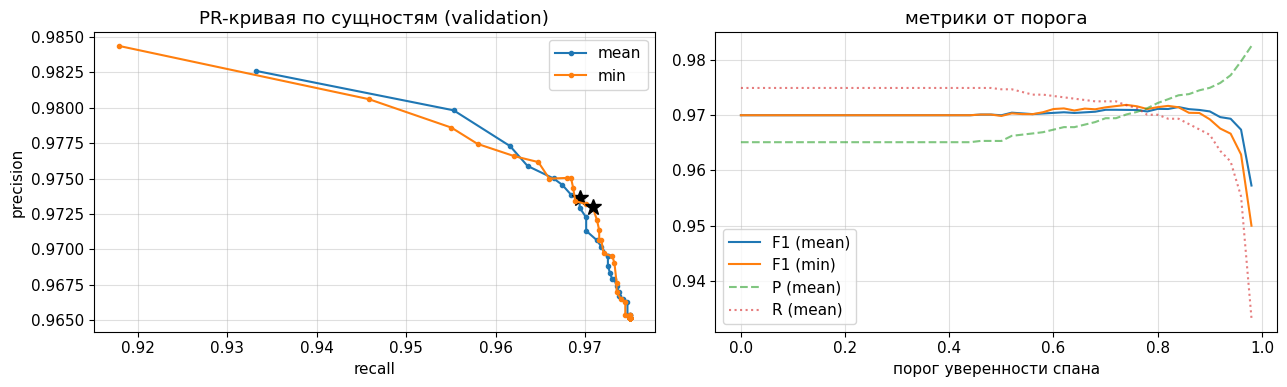

In [ ]:
if '6.5' in BONUS_TASKS:
    tags_v, probs_v = predict_word_tags(model, val_tokens, return_probs=True)
    gold_all = {(i, *s) for i, tags in enumerate(val_gold) for s in bio_to_spans(tags)}

    def scored_spans(how):
        reduce = np.mean if how == 'mean' else np.min
        return [((i, *s), float(reduce(probs[s[0]:s[1]]))) for i, (tags, probs) in enumerate(zip(tags_v, probs_v))
                for s in bio_to_spans(tags)]

    def prf(spans, thr):
        kept = [s for s, c in spans if c >= thr]
        tp = sum(s in gold_all for s in kept)
        p = tp / len(kept) if kept else 0.0
        r = tp / len(gold_all)
        return p, r, 2 * p * r / (p + r) if tp else 0.0

    thresholds = np.round(np.arange(0, 1.0, 0.02), 2)
    curves, best = {}, {}
    for how in ('mean', 'min'):
        spans = scored_spans(how)
        curves[how] = np.array([prf(spans, t) for t in thresholds])
        k = int(curves[how][:, 2].argmax())
        best[how] = dict(threshold=float(thresholds[k]), precision=float(curves[how][k, 0]),
                         recall=float(curves[how][k, 1]), f1=float(curves[how][k, 2]), f1_at_0=float(curves[how][0, 2]))
    print(f'проверка: F1 при пороге 0 = {best["mean"]["f1_at_0"]:.6f}, seqeval F1 = {f1_score(val_gold, tags_v, zero_division=0):.6f}')
    for how, b in best.items():
        print(f'{how}: лучший порог {b["threshold"]:.2f}, F1 {b["f1"]:.4f} (P {b["precision"]:.4f}, R {b["recall"]:.4f}), '
              f'при пороге 0: F1 {b["f1_at_0"]:.4f}, прирост {b["f1"] - b["f1_at_0"]:+.4f}')

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for how in ('mean', 'min'):
        c = curves[how]
        axes[0].plot(c[:, 1], c[:, 0], '.-', label=f'{how}')
        axes[0].plot(best[how]['recall'], best[how]['precision'], 'k*', markersize=12)
        axes[1].plot(thresholds, c[:, 2], label=f'F1 ({how})')
    axes[1].plot(thresholds, curves['mean'][:, 0], '--', alpha=0.6, label='P (mean)')
    axes[1].plot(thresholds, curves['mean'][:, 1], ':', alpha=0.6, label='R (mean)')
    axes[0].set_xlabel('recall')
    axes[0].set_ylabel('precision')
    axes[0].set_title('PR-кривая по сущностям (validation)')
    axes[0].legend()
    axes[1].set_xlabel('порог уверенности спана')
    axes[1].set_title('метрики от порога')
    axes[1].legend()
    for ax in axes:
        ax.grid(True, alpha=0.4)
    plt.tight_layout()
    plt.show()
    BONUS_RESULTS['6.5'] = best

**Вопрос.** Какой порог дает лучший F1 и сколько он добавляет к порогу 0? Чем отличаются средняя и минимальная уверенность? Почему порог по уверенности не может поднять recall?

**Ответ:** Для каждой найденной сущности считаю уверенность модели (среднюю или минимальную по её словам) и отбрасываю сущности с уверенностью ниже порога.

Лучший результат: по средней уверенности порог 0.84 даёт F1 0.9715, по минимальной порог 0.74 даёт F1 0.9719. Без порога было 0.9700, так что прирост совсем маленький (+0.0015 и +0.0019): модель и так почти во всём уверена.

Минимальная уверенность строже средней: сущность отбрасывается, если модель не уверена хотя бы в одном её слове. Поэтому оптимальный порог у неё ниже.

С ростом порога recall может только падать: порог убирает сущности, но не может добавить новые. А precision при этом растёт, потому что убираются в основном неуверенные (часто ошибочные) сущности.

In [ ]:
if BONUS_RESULTS:
    (ARTIFACTS / 'bonus_metrics.json').write_text(json.dumps(json_ready(dict(fast_mode=FAST_MODE, run_times=RUN_TIMES, **BONUS_RESULTS)),
                                                             ensure_ascii=False, indent=2), encoding='utf-8')
    print('Сохранено: artifacts/bonus_metrics.json, бонусы', sorted(BONUS_RESULTS))

Сохранено: artifacts/bonus_metrics.json, бонусы ['6.2', '6.3', '6.4', '6.5']


In [ ]:
!zip -r artifacts.zip artifacts
from google.colab import files
files.download('artifacts.zip')

updating: artifacts/ (stored 0%)
updating: artifacts/metrics.json (deflated 61%)
updating: artifacts/bonus_metrics.json (deflated 68%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>